# **Business Context**


Renewable energy sources play an increasingly important role in the global energy mix, as the effort to reduce the environmental impact of energy production increases.

Out of all the renewable energy alternatives, wind energy is one of the most developed technologies worldwide. The U.S. Department of Energy has put together a guide to achieving operational efficiency using predictive maintenance practices.

Predictive maintenance uses sensor information and analysis methods to measure and predict degradation and future component capability. The idea behind predictive maintenance is that failure patterns are predictable and if component failure can be predicted accurately and the component is replaced before it fails, the costs of operation and maintenance will be much lower.

The sensors fitted across different machines involved in the process of energy generation collect data related to various environmental factors (temperature, humidity, wind speed, etc.) and additional features related to various parts of the wind turbine (gearbox, tower, blades, break, etc.).

## **Objective**

“ReneWind” is a company working on improving the machinery/processes involved in the production of wind energy using machine learning and has collected data on generator failure of wind turbines using sensors. They have shared a ciphered version of the data, as the data collected through sensors is confidential (the type of data collected varies with companies). Data has 40 predictors, 20000 observations in the training set, and 5000 in the test set.

The objective is to build various classification models, tune them, and find the best one that will help identify failures so that the generators can be repaired before failing/breaking to reduce the overall maintenance cost.
The nature of predictions made by the classification model will translate as follows:

True positives (TP) are failures correctly predicted by the model. These will result in repair costs.
False negatives (FN) are real failures where there is no detection by the model. These will result in replacement costs.
False positives (FP) are detections where there is no failure. These will result in inspection costs.
It is given that the cost of repairing a generator is much less than the cost of replacing it, and the cost of inspection is less than the cost of repair.

“1” in the target variable should be considered as “failure” and “0” represents “No failure”.

## **Data Dictionary**

The data provided is a transformed version of the original data which was collected using sensors.

Train.csv - To be used for training and tuning of models.
Test.csv - To be used only for testing the performance of the final best model.
Both datasets consist of 40 predictor variables and 1 target variable.

# **Importing Necessary Libraries**

In [1]:
# Library for data manipulation and analysis.
import pandas as pd

# Fundamental package for scientific computing.
import numpy as np

#splitting datasets into training and testing sets.
from sklearn.model_selection import train_test_split

#Imports tools for data preprocessing including label encoding, one-hot encoding, and standard scaling
from sklearn.preprocessing import LabelEncoder, OneHotEncoder,StandardScaler

#Imports a class for imputing missing values in datasets.
from sklearn.impute import SimpleImputer

#Imports the Matplotlib library for creating visualizations.
import matplotlib.pyplot as plt

# Imports the Seaborn library for statistical data visualization.
import seaborn as sns

# Time related functions.
import time

#Imports functions for evaluating the performance of machine learning models
from sklearn.metrics import confusion_matrix, f1_score,accuracy_score, recall_score, precision_score, classification_report

In [2]:
pip install "tensorstore>=0.1.71"

In [3]:
pip install tensorflow==2.19.0 tensorflow-decision-forests==1.12.0 tf-keras==2.19.0 tensorflow-text==2.19.0 ml-dtypes>=0.5.0


In [4]:
#Imports the tensorflow,keras and layers.
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dense, Input, Dropout,BatchNormalization
from tensorflow.keras import backend
import tensorflow as tf

# to suppress unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

In [5]:
tf.keras.utils.set_random_seed(812)
tf.config.experimental.enable_op_determinism()

**Importing datasets**

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Reading Dataset and taking the copy of dataset**

In [7]:
data = pd.read_csv('/content/drive/MyDrive/Artificial intelligence(AI) & Machine Learning(ML) /Module 04 : Introduction to Neural Networks/Week 3 : Neural  Network Project/Train.csv')

In [8]:
df = data.copy()

# **Data Overview**

Reading the Head and Tail of the Dataset

In [9]:
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
0,-4.464606,-4.679129,3.101546,0.506130,-0.221083,-2.032511,-2.910870,0.050714,-1.522351,3.761892,...,3.059700,-1.690440,2.846296,2.235198,6.667486,0.443809,-2.369169,2.950578,-3.480324,0
1,3.365912,3.653381,0.909671,-1.367528,0.332016,2.358938,0.732600,-4.332135,0.565695,-0.101080,...,-1.795474,3.032780,-2.467514,1.894599,-2.297780,-1.731048,5.908837,-0.386345,0.616242,0
2,-3.831843,-5.824444,0.634031,-2.418815,-1.773827,1.016824,-2.098941,-3.173204,-2.081860,5.392621,...,-0.257101,0.803550,4.086219,2.292138,5.360850,0.351993,2.940021,3.839160,-4.309402,0
3,1.618098,1.888342,7.046143,-1.147285,0.083080,-1.529780,0.207309,-2.493629,0.344926,2.118578,...,-3.584425,-2.577474,1.363769,0.622714,5.550100,-1.526796,0.138853,3.101430,-1.277378,0
4,-0.111440,3.872488,-3.758361,-2.982897,3.792714,0.544960,0.205433,4.848994,-1.854920,-6.220023,...,8.265896,6.629213,-10.068689,1.222987,-3.229763,1.686909,-2.163896,-3.644622,6.510338,0


In [10]:
df.tail()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
19995,-2.071318,-1.088279,-0.796174,-3.011720,-2.287540,2.807310,0.481428,0.105171,-0.586599,-2.899398,...,-8.273996,5.745013,0.589014,-0.649988,-3.043174,2.216461,0.608723,0.178193,2.927755,1
19996,2.890264,2.483069,5.643919,0.937053,-1.380870,0.412051,-1.593386,-5.762498,2.150096,0.272302,...,-4.159092,1.181466,-0.742412,5.368979,-0.693028,-1.668971,3.659954,0.819863,-1.987265,0
19997,-3.896979,-3.942407,-0.351364,-2.417462,1.107546,-1.527623,-3.519882,2.054792,-0.233996,-0.357687,...,7.112162,1.476080,-3.953710,1.855555,5.029209,2.082588,-6.409304,1.477138,-0.874148,0
19998,-3.187322,-10.051662,5.695955,-4.370053,-5.354758,-1.873044,-3.947210,0.679420,-2.389254,5.456756,...,0.402812,3.163661,3.752095,8.529894,8.450626,0.203958,-7.129918,4.249394,-6.112267,0
19999,-2.686903,1.961187,6.137088,2.600133,2.657241,-4.290882,-2.344267,0.974004,-1.027462,0.497421,...,6.620811,-1.988786,-1.348901,3.951801,5.449706,-0.455411,-2.202056,1.678229,-1.974413,0


**Checking for Missing values**

In [11]:
df.isnull().sum()

,0
V1,18
V2,18
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0
V10,0


* By checking the missing values in the given dataset, found that columns "V1" & "V2" has 18 missing records in alternative rows

**Percentage of Missing value in each columns**

In [12]:
df.isnull().sum()/df.count()*100

,0
V1,0.090081
V2,0.090081
V3,0.000000
V4,0.000000
V5,0.000000
V6,0.000000
V7,0.000000
V8,0.000000
V9,0.000000
V10,0.000000


* By checking the percentage of missing values in the given dataset, found that columns "V1" & "V2" has 9% missing records

**Checking for Duplicated values**

In [13]:
df.duplicated().sum()

np.int64(0)

* There is no duplicate value in the given dataset

**Checking the shape of the dataset**

In [14]:
df.shape

(20000, 41)

* Dataset has 20000 rows with 41 columns

**Checking the columns types and not null values for the dataset**

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 41 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   V1      19982 non-null  float64
 1   V2      19982 non-null  float64
 2   V3      20000 non-null  float64
 3   V4      20000 non-null  float64
 4   V5      20000 non-null  float64
 5   V6      20000 non-null  float64
 6   V7      20000 non-null  float64
 7   V8      20000 non-null  float64
 8   V9      20000 non-null  float64
 9   V10     20000 non-null  float64
 10  V11     20000 non-null  float64
 11  V12     20000 non-null  float64
 12  V13     20000 non-null  float64
 13  V14     20000 non-null  float64
 14  V15     20000 non-null  float64
 15  V16     20000 non-null  float64
 16  V17     20000 non-null  float64
 17  V18     20000 non-null  float64
 18  V19     20000 non-null  float64
 19  V20     20000 non-null  float64
 20  V21     20000 non-null  float64
 21  V22     20000 non-null  float64
 22

* The columns "V1" & "V2" has 18 missing records, all the columns in the datasets are Numerical

**Checking for unique values in the Target column**

In [16]:
#Number of distinct categories or classes i.e., Fraudulent and Genuine
print(df['Target'].nunique())
print(df['Target'].unique())

2
[0 1]


* There are two unique values in the Taget column and they are 0 & 1,
* where 0 represents 'No Failure' and 1 represents 'Failure'

**Checking the Dataset is balanced or imbalanced**

In [17]:
#checking the percentage of each class in the dataset
print((df.Target.value_counts())/(df.Target.count()))
print('\n')
print(df.Target.value_counts())

Target
0    0.9445
1    0.0555
Name: count, dtype: float64


Target
0    18890
1     1110
Name: count, dtype: int64


* This shows a complete imbalance of classes. There are 94.44% 'No Failure'(0) instances and only 5.6% 'Failure' (1) instances. This means that we are aiming to predict anomalous events.

* The target column in the given dataset contains mostly of data of No failure
where few data of Failure

## **Checking the Statistical summary of the dataset**

In [18]:
df.describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
count,19982.000000,19982.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,...,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,-0.271996,0.440430,2.484699,-0.083152,-0.053752,-0.995443,-0.879325,-0.548195,-0.016808,-0.012998,...,0.303799,0.049825,-0.462702,2.229620,1.514809,0.011316,-0.344025,0.890653,-0.875630,0.055500
std,3.441625,3.150784,3.388963,3.431595,2.104801,2.040970,1.761626,3.295756,2.160568,2.193201,...,5.500400,3.575285,3.183841,2.937102,3.800860,1.788165,3.948147,1.753054,3.012155,0.228959
min,-11.876451,-12.319951,-10.708139,-15.082052,-8.603361,-10.227147,-7.949681,-15.657561,-8.596313,-9.853957,...,-19.876502,-16.898353,-17.985094,-15.349803,-14.833178,-5.478350,-17.375002,-6.438880,-11.023935,0.000000
25%,-2.737146,-1.640674,0.206860,-2.347660,-1.535607,-2.347238,-2.030926,-2.642665,-1.494973,-1.411212,...,-3.420469,-2.242857,-2.136984,0.336191,-0.943809,-1.255819,-2.987638,-0.272250,-2.940193,0.000000
50%,-0.747917,0.471536,2.255786,-0.135241,-0.101952,-1.000515,-0.917179,-0.389085,-0.067597,0.100973,...,0.052073,-0.066249,-0.255008,2.098633,1.566526,-0.128435,-0.316849,0.919261,-0.920806,0.000000
75%,1.840112,2.543967,4.566165,2.130615,1.340480,0.380330,0.223695,1.722965,1.409203,1.477045,...,3.761722,2.255134,1.436935,4.064358,3.983939,1.175533,2.279399,2.057540,1.119897,0.000000
max,15.493002,13.089269,17.090919,13.236381,8.133797,6.975847,8.006091,11.679495,8.137580,8.108472,...,23.633187,16.692486,14.358213,15.291065,19.329576,7.467006,15.289923,7.759877,10.654265,1.000000


 * The minimum values in the given dataset across of all columns ranges between -5.47835049 to -20.37415806
 * The maximum values in the given dataset across of all columns ranges between 6.527643158 to 17.25509041
 * The mean values of all columns for the given dataset ranges between        -3.6112515777463 to 2.48469929426655
 * The Standard deviation values of all columns for the given dataset ranges between 1.7530536518167164 to 5.5004001383043635

# **Exploratory Data Analysis (EDA) Summary**

### **Univarite Analysis**

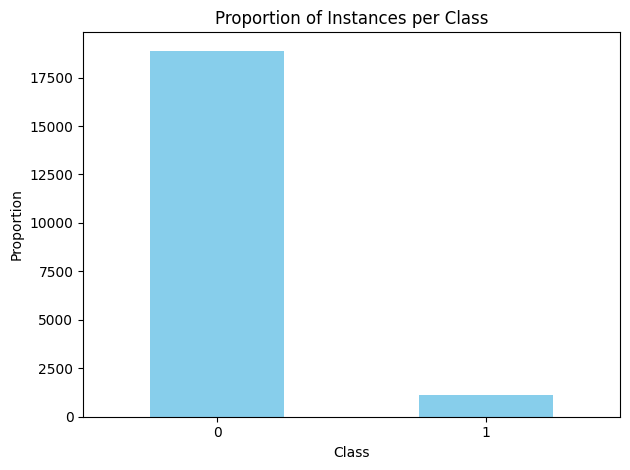

In [19]:
# Assuming df is your DataFrame and 'Target' is the class column
class_counts = df['Target'].value_counts()  # Get proportions
class_counts.plot(kind='bar', color='skyblue')

plt.title('Proportion of Instances per Class')
plt.xlabel('Class')
plt.ylabel('Proportion')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


* The univariate analysis on the target column tells us that almost 18000 records are based on NO Failure and remaining 2000 records are based on Failure

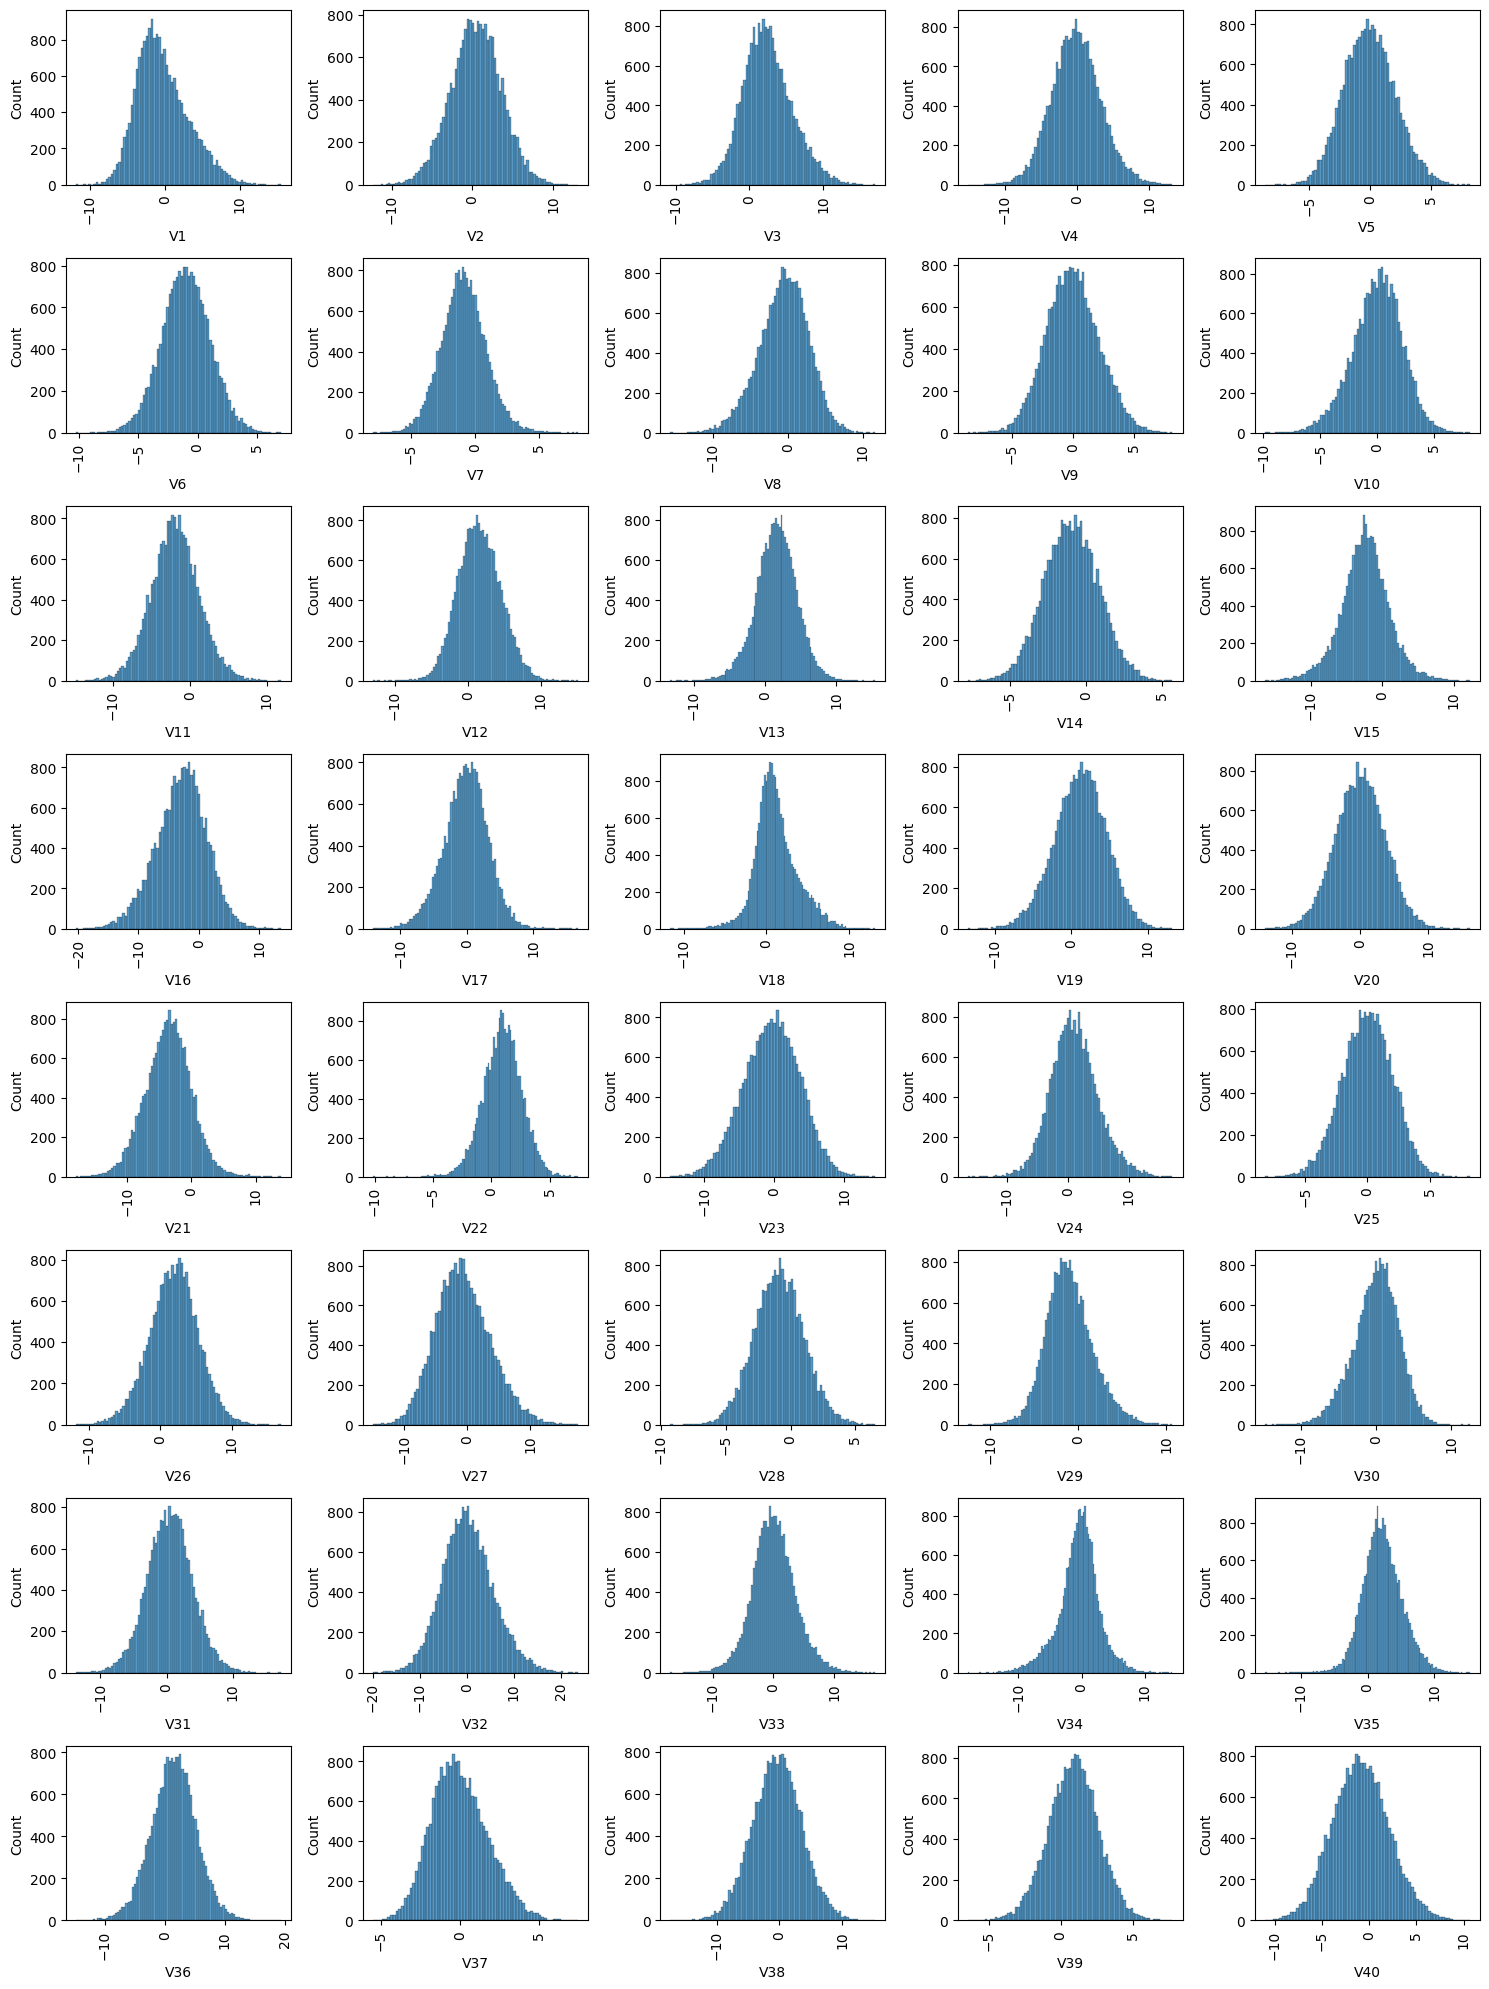

In [20]:
ep = ['V1','V2','V3','V4','V5','V6','V7','V8','V9','V10',
      'V11','V12','V13','V14','V15','V16','V17','V18','V19','V20',
      'V21','V22','V23','V24','V25','V26','V27','V28','V29','V30',
      'V31','V32','V33','V34','V35','V36','V37','V38','V39','V40',]


plt.figure(figsize=(15, 20))  # increase height to fit more plots
for i, feature in enumerate(ep):
    plt.subplot(8, 5, i + 1)  # 8 rows, 5 columns for 40 features
    sns.histplot(data=df, x=feature)
    plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


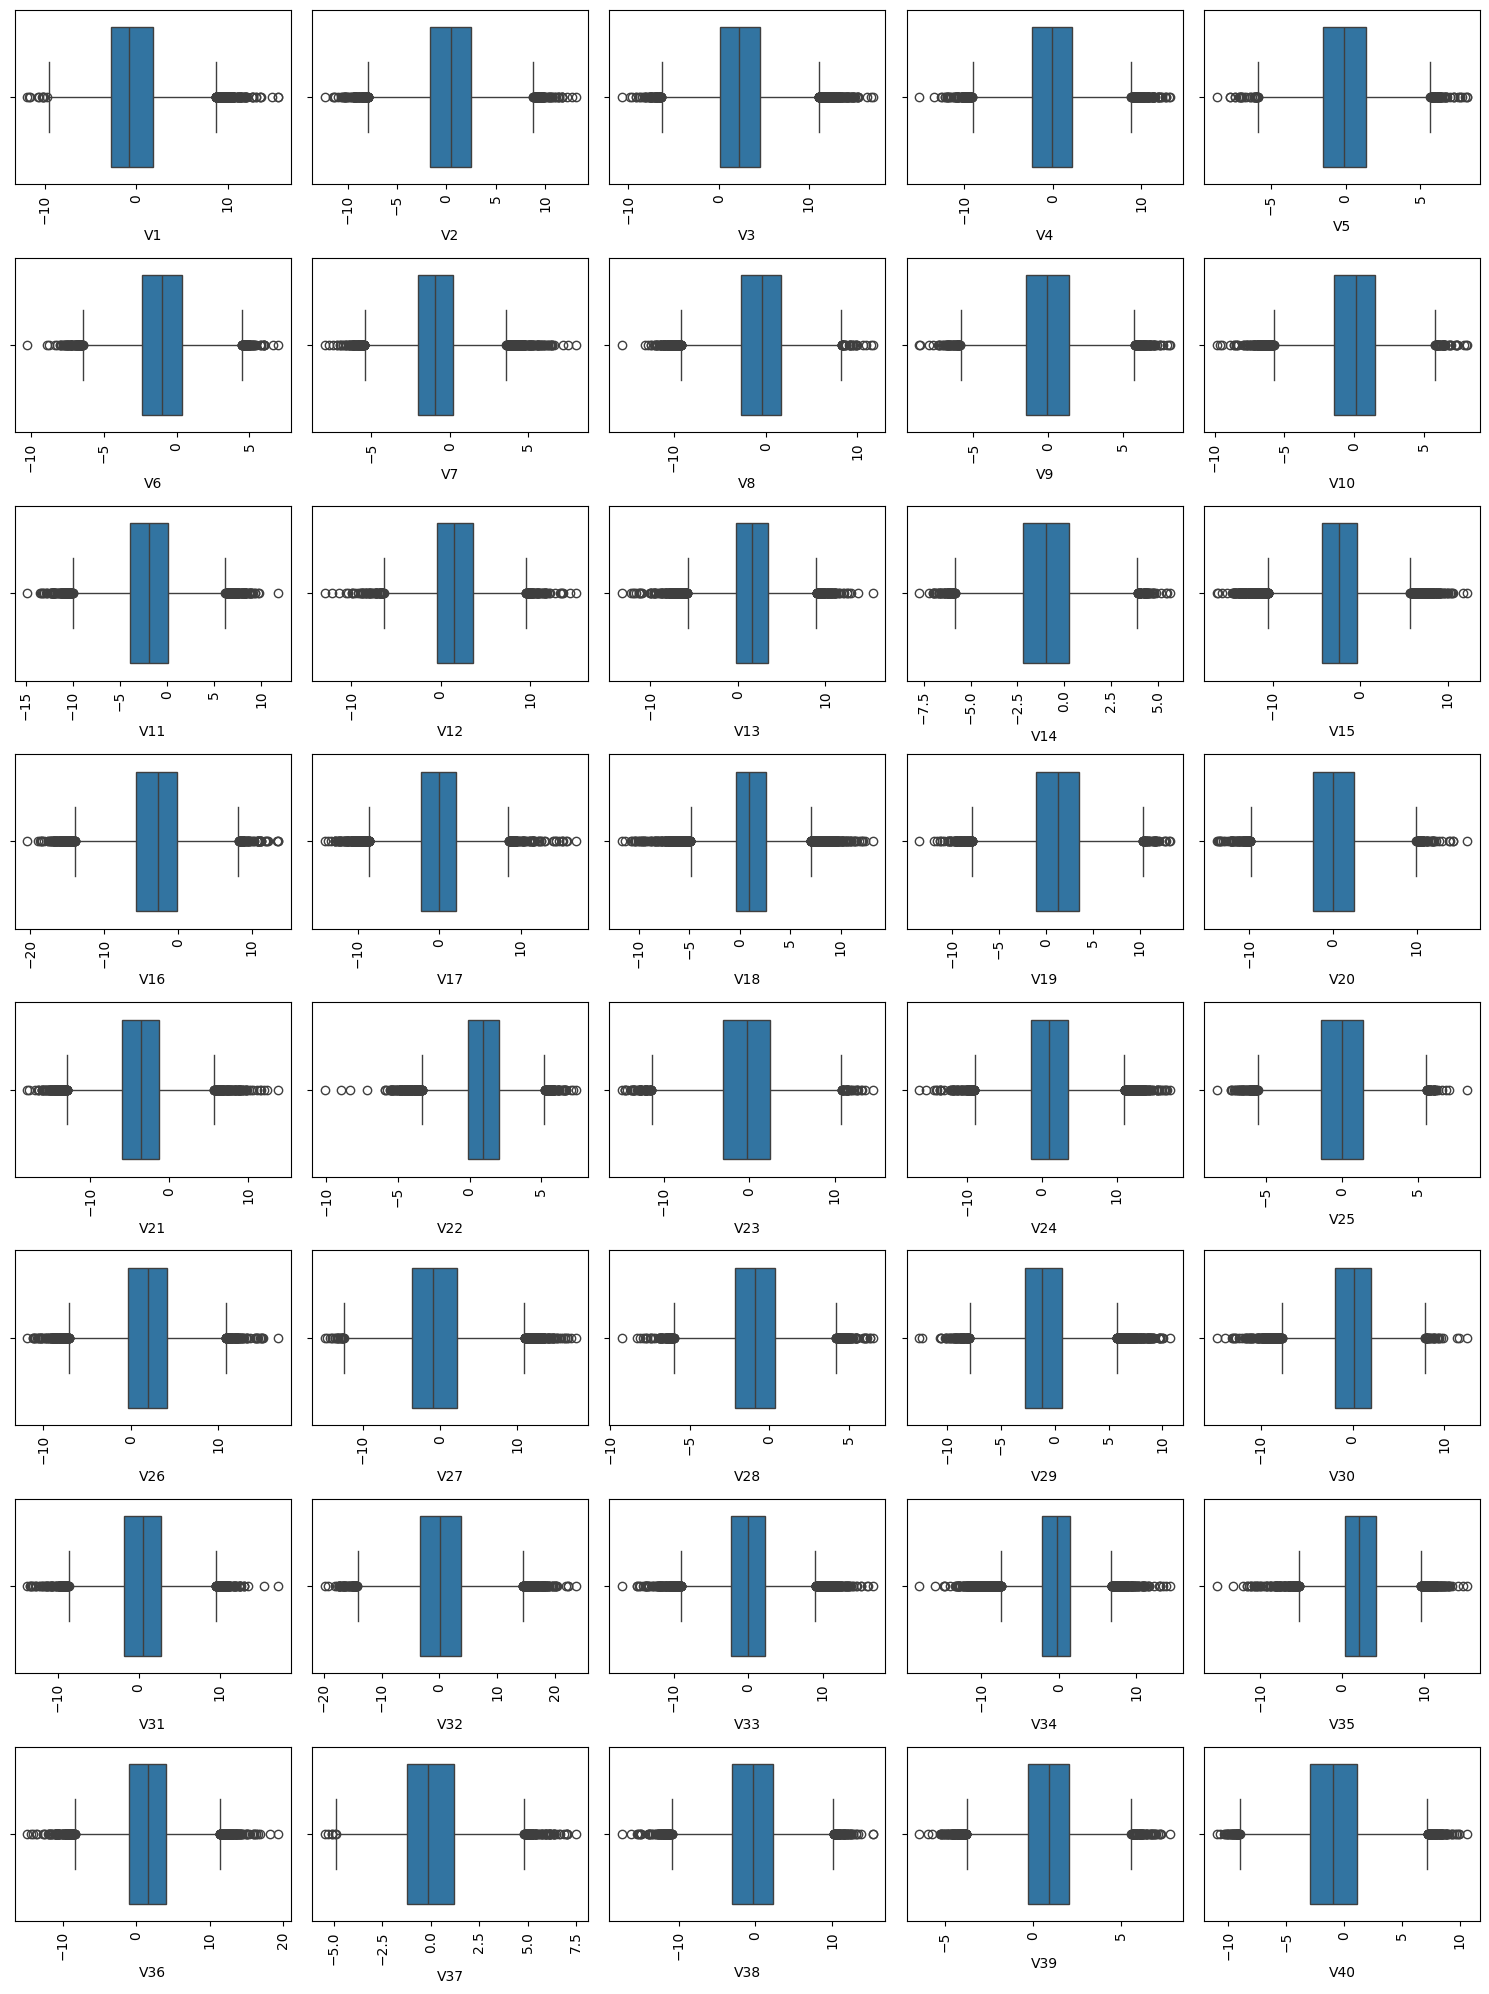

In [21]:
plt.figure(figsize=(15, 20))  # increase height to fit more plots
for i, feature in enumerate(ep):
    plt.subplot(8, 5, i + 1)  # 8 rows, 5 columns for 40 features
    sns.boxplot(data=df, x=feature)
    plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


* The boxplot shows the there is presence of outliers in every column, becausethe given data is based upon sensor value these outliers cannot be treated

**Bivariate Analysis**

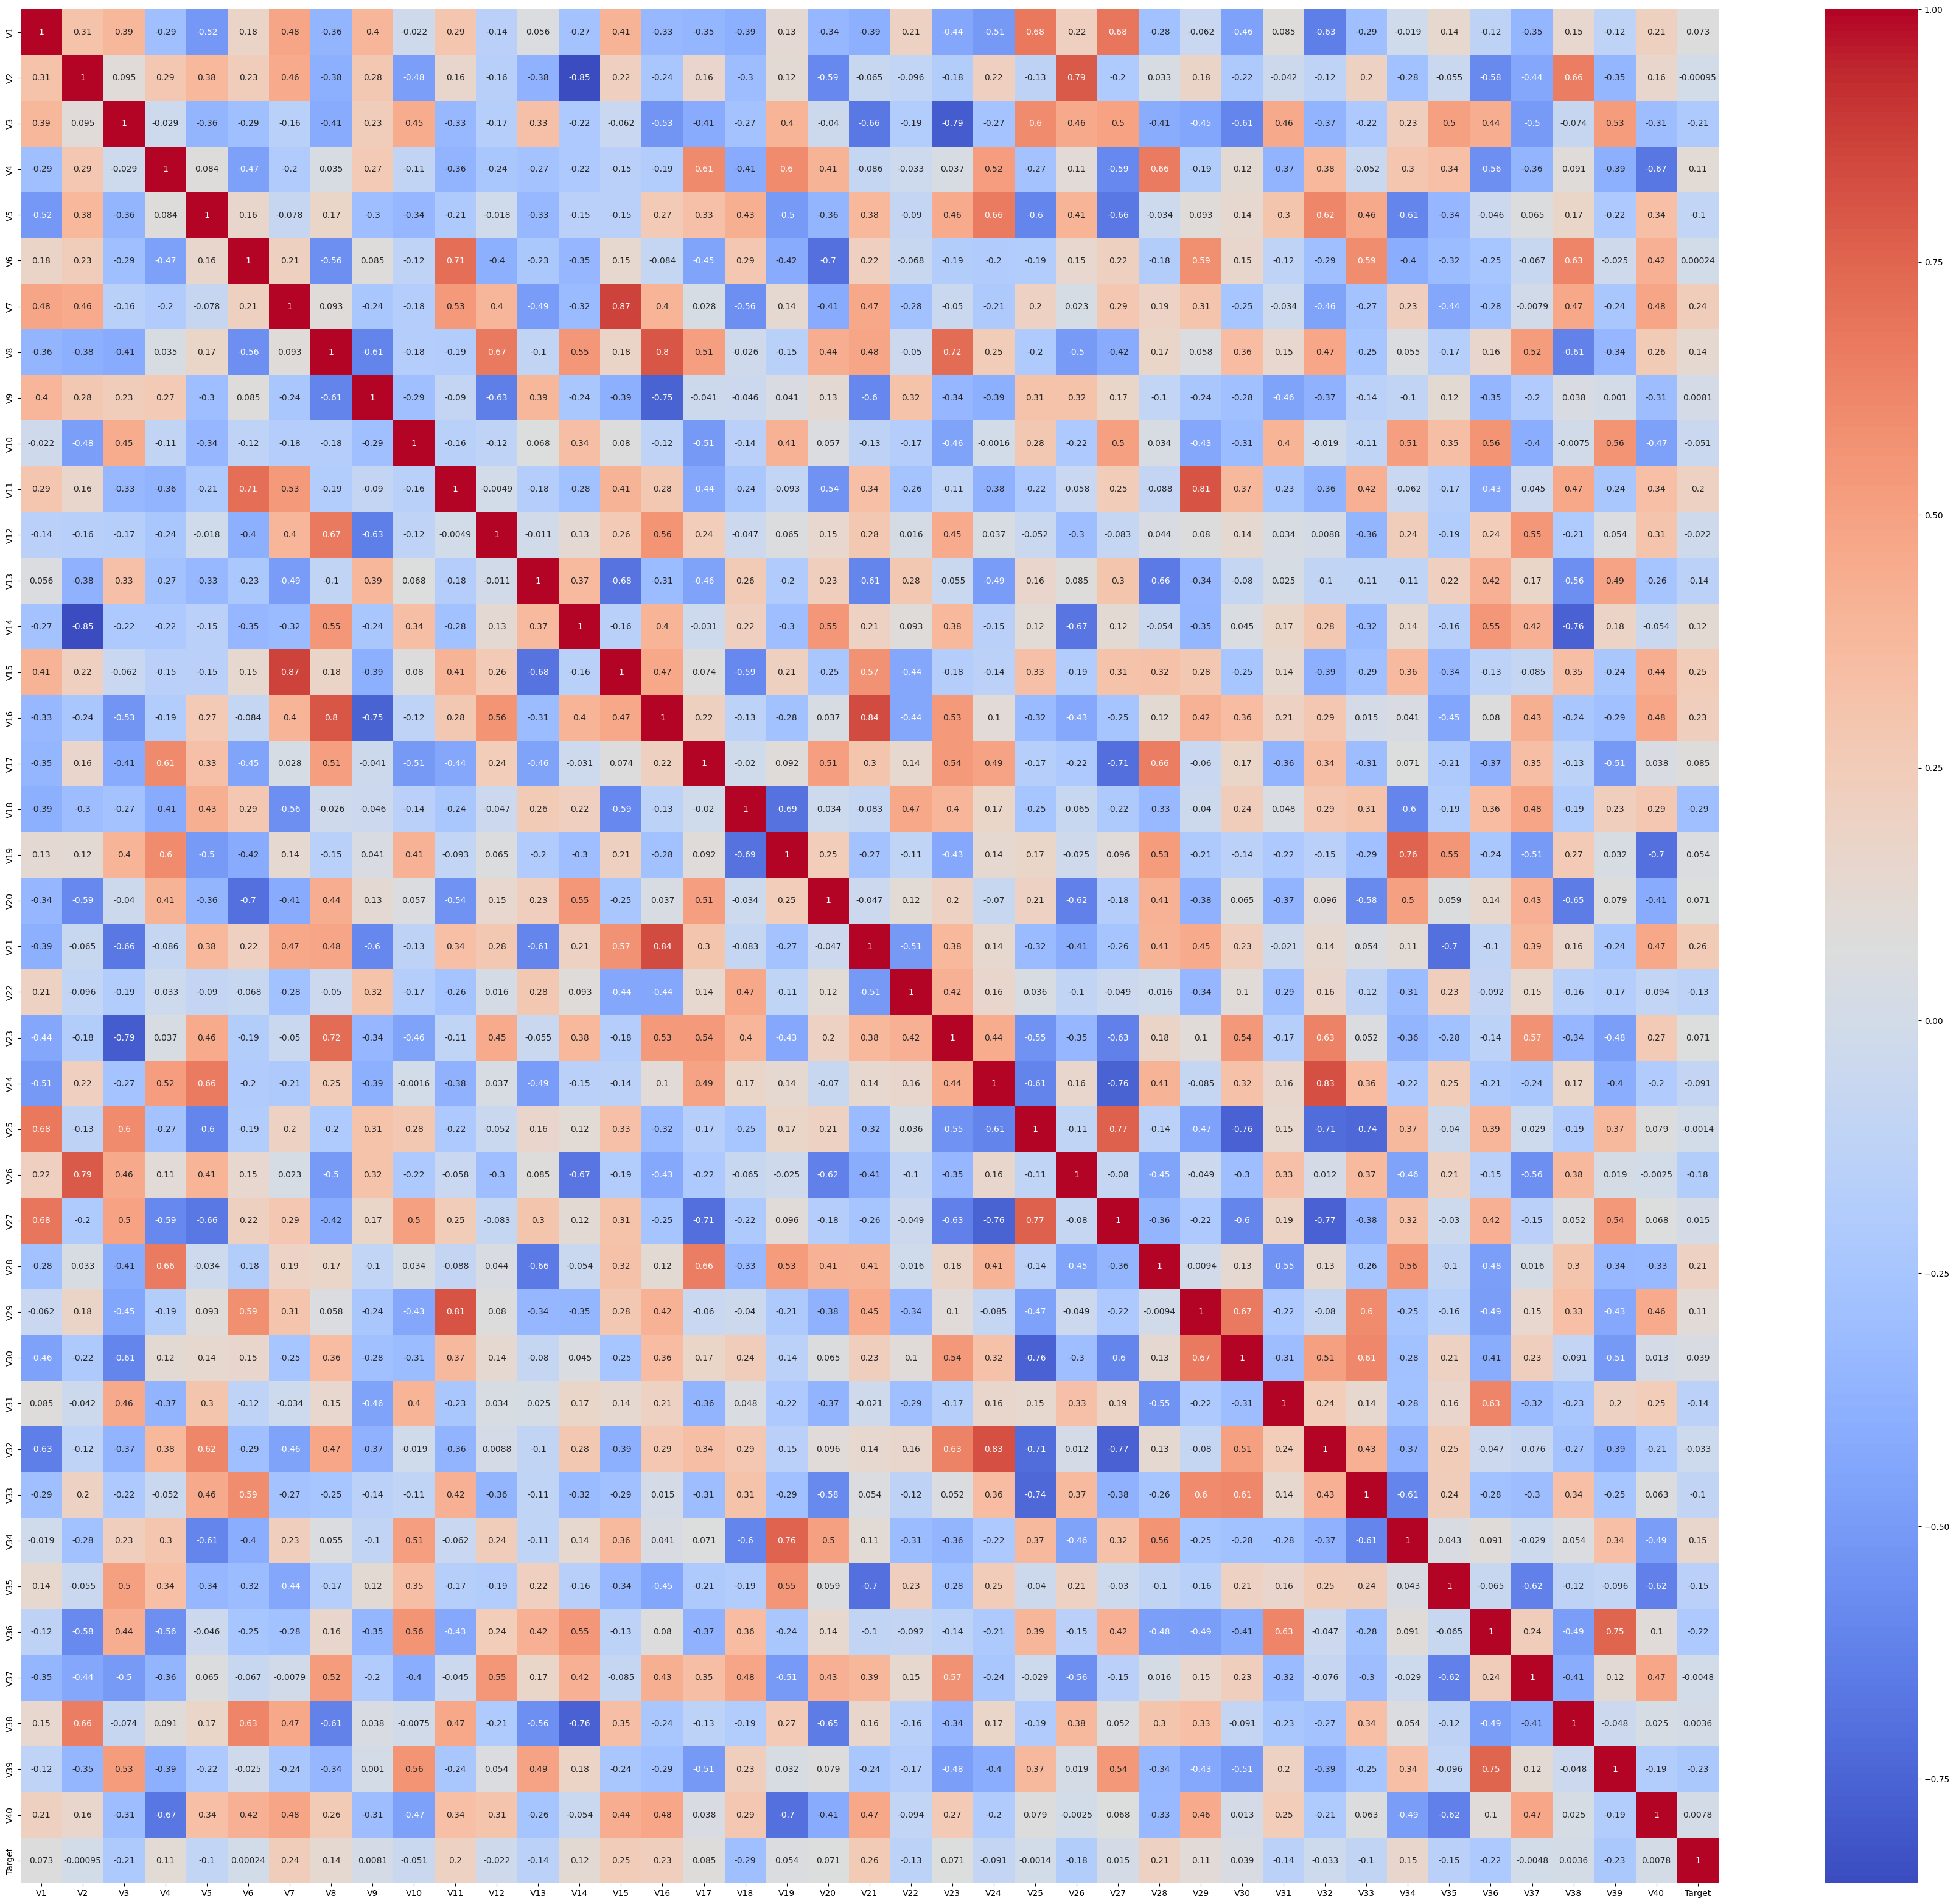

In [22]:
plt.figure(figsize=(45, 40))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.show()

* The heatmap shows the correlation between every columns in the given dataset

# **Data Preprocessing**

**Missing Value treatment**

In [23]:
df.shape

(20000, 41)

* Before treating the missing value lets check the shape of dataset
  * the dataset contains 20000 rows,and 41 columns

In [24]:
filter = df[df['V1'].isna()]
print(filter)

       V1        V2        V3        V4        V5        V6        V7  \
89    NaN -3.961403  2.787804 -4.712526 -3.007329 -1.541245 -0.881148   
5941  NaN  1.008391  1.227702  5.397082  0.064230 -2.706919 -2.028368   
6317  NaN -5.205346  1.997652 -3.707913 -1.042200 -1.593126 -2.653309   
6464  NaN  2.146202  5.004415  4.192063  1.427887 -6.438263 -0.931339   
7073  NaN  2.534010  2.762821 -1.673718 -1.942214 -0.029961  0.911323   
8431  NaN -1.398710 -2.008106 -1.750341  0.932279 -1.290327 -0.270476   
8439  NaN -3.840585  0.197220  4.147789  1.151400 -0.993298 -4.732363   
11156 NaN -0.666978  3.715829  4.934000  1.667596 -4.356097 -2.823137   
11287 NaN -2.561519 -0.180836 -7.194814 -1.043832  1.384845  1.306093   
11456 NaN  1.299595  4.382858  1.583219 -0.076564  0.658770 -1.638530   
12221 NaN -2.326319 -0.051978  0.615063 -0.895755 -2.437003  0.349826   
12447 NaN  0.752613 -0.271099  1.301204  2.038697 -1.485203 -0.411939   
13086 NaN  2.056243  3.330642  2.741497  2.783166 -

In [25]:
df = df.drop(filter.index).reset_index(drop=True)

* the Nan value are filtered from the "V1" column and those columns are droped from the dataset. Because dataset contains data from the sensor of machinary which vary according to performance of the machine   

In [26]:
df.shape

(19982, 41)

In [27]:
filter1 = df[df['V2'].isna()]
print(filter1)

             V1  V2        V3        V4        V5        V6        V7  \
612   -2.048681 NaN -1.623885 -3.324224  0.152256  0.600157 -1.812802   
2235  -3.760658 NaN  0.194954 -1.637958  1.261479 -1.573947 -3.685700   
2507  -1.430888 NaN  0.659576 -2.876402  1.150137 -0.785760 -1.560174   
4652   5.465769 NaN  4.540947 -2.916550  0.399752  2.798925  0.029477   
6806  -2.631454 NaN  2.330188  1.090080  0.603973 -1.139383 -0.690121   
7783  -4.203459 NaN  2.953868  0.584466  4.103940 -0.639211 -2.810799   
8476  -4.484232 NaN  1.200644 -2.042064  2.779443 -0.801748 -5.403548   
8887   3.263555 NaN  8.446574 -3.253218 -3.417978 -2.995838 -0.669271   
8940  -3.793170 NaN  0.719610  2.306296  0.934728 -0.984321  0.504867   
9355   2.662045 NaN  2.980068  4.430762 -0.237769  0.671919  0.380068   
9418  -2.354134 NaN  2.053893  0.811660  2.540366 -0.924875 -0.208380   
9841  -1.763501 NaN  2.845012 -2.753083 -0.811848 -0.101166 -1.382141   
11627 -2.270541 NaN  1.710061  1.157522 -0.355177 -

In [28]:
df = df.drop(filter1.index).reset_index(drop=True)

* the Nan value are filtered from the "V2" column and those columns are droped from the dataset. Because dataset contains data from the sensor of machinary which vary according to performance of the machine   

In [29]:
df.shape

(19964, 41)

* The total of 36 alternative rows in the V1 and V2 columns has missing value, so the rows has been dropped

**Splitting the dataset**

In [30]:
## Separating Independent and Dependent Columns
X = df.drop(['Target'],axis=1)
y = df['Target']

In [31]:
# Splitting data into training, validation and test set:
# first we split data into 2 parts, say temporary and test

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=1, stratify=y)

# then we split the temporary set into train and validation

X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=1, stratify=y_temp)

* The data in the dataset is split into Training, Validation and Testing  

In [32]:
print("Number of rows in train data =", X_train.shape[0])
print("Number of rows in validation data =", X_val.shape[0])
print("Number of rows in test data =", X_test.shape[0])

Number of rows in train data = 11978
Number of rows in validation data = 3993
Number of rows in test data = 3993


* After spliting the dataset into Training,Validation and Test without Target columns
  * The number of rows in the training set are 11978
  * The number of rows in the validation set are 3993
  * The number of rows in the testing set are 3993

In [33]:
print("Number of rows in train data =", y_train.shape[0])
print("Number of rows in validation data =", y_val.shape[0])
print("Number of rows in test data =", y_test.shape[0])

Number of rows in train data = 11978
Number of rows in validation data = 3993
Number of rows in test data = 3993


* After spliting the dataset into Training,Validation and Testing data of the  Target columns
  * The number of rows in the training set are 11978
  * The number of rows in the validation set are 3993
  * The number of rows in the testing set are 3993

# **Utility function**

In [34]:
# defining a function to compute different metrics to check performance of a classification model built using sklearn
def model_performance_classification_sklearn(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred)  # to compute Recall
    precision = precision_score(target, pred)  # to compute Precision
    f1 = f1_score(target, pred)  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1": f1,},
        index=[0],
    )

    return df_perf

In [35]:
def make_confusion_matrix(cf,
                          group_names=None,
                          categories='auto',
                          count=True,
                          percent=True,
                          cbar=True,
                          xyticks=True,
                          xyplotlabels=True,
                          sum_stats=True,
                          figsize=None,
                          cmap='Blues',
                          title=None):
    '''
    This function will make a pretty plot of an sklearn Confusion Matrix cm using a Seaborn heatmap visualization.
    Arguments
    '''


    # CODE TO GENERATE TEXT INSIDE EACH SQUARE
    blanks = ['' for i in range(cf.size)]

    if group_names and len(group_names)==cf.size:
        group_labels = ["{}\n".format(value) for value in group_names]
    else:
        group_labels = blanks

    if count:
        group_counts = ["{0:0.0f}\n".format(value) for value in cf.flatten()]
    else:
        group_counts = blanks

    if percent:
        group_percentages = ["{0:.2%}".format(value) for value in cf.flatten()/np.sum(cf)]
    else:
        group_percentages = blanks

    box_labels = [f"{v1}{v2}{v3}".strip() for v1, v2, v3 in zip(group_labels,group_counts,group_percentages)]
    box_labels = np.asarray(box_labels).reshape(cf.shape[0],cf.shape[1])


    # CODE TO GENERATE SUMMARY STATISTICS & TEXT FOR SUMMARY STATS
    if sum_stats:
        #Accuracy is sum of diagonal divided by total observations
        accuracy  = np.trace(cf) / float(np.sum(cf))

        #if it is a binary confusion matrix, show some more stats
        if len(cf)==2:
            #Metrics for Binary Confusion Matrices
            precision = cf[1,1] / sum(cf[:,1])
            recall    = cf[1,1] / sum(cf[1,:])
            f1_score  = 2*precision*recall / (precision + recall)
            stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
                accuracy,precision,recall,f1_score)
        else:
            stats_text = "\n\nAccuracy={:0.3f}".format(accuracy)
    else:
        stats_text = ""


    # SET FIGURE PARAMETERS ACCORDING TO OTHER ARGUMENTS
    if figsize==None:
        #Get default figure size if not set
        figsize = plt.rcParams.get('figure.figsize')

    if xyticks==False:
        #Do not show categories if xyticks is False
        categories=False


    # MAKE THE HEATMAP VISUALIZATION
    plt.figure(figsize=figsize)
    sns.heatmap(cf,annot=box_labels,fmt="",cmap=cmap,cbar=cbar,xticklabels=categories,yticklabels=categories)

    if xyplotlabels:
        plt.ylabel('True label')
        plt.xlabel('Predicted label' + stats_text)
    else:
        plt.xlabel(stats_text)

    if title:
        plt.title(title)

In [36]:
def plot(history, name):
    """
    Function to plot loss/accuracy

    history: an object which stores the metrics and losses.
    name: can be one of Loss or Accuracy
    """
    fig, ax = plt.subplots() #Creating a subplot with figure and axes.
    plt.plot(history.history[name]) #Plotting the train accuracy or train loss
    plt.plot(history.history['val_'+name]) #Plotting the validation accuracy or validation loss

    plt.title('Model ' + name.capitalize()) #Defining the title of the plot.
    plt.ylabel(name.capitalize()) #Capitalizing the first letter.
    plt.xlabel('Epoch') #Defining the label for the x-axis.
    fig.legend(['Train', 'Validation'], loc="outside right upper") #Defining the legend, loc controls the position of the legend.

# **Model Building**

In [37]:
from sklearn.ensemble import RandomForestClassifier

In [38]:
random_forest = RandomForestClassifier(n_estimators=100).fit(X_train,y_train)

In [39]:
RandomForestClassifier()

RandomForestClassifier()

In [40]:
y_pred = random_forest.predict(X_test)

In [41]:
random_forest.score(X_test,y_test)

0.9844728274480341

* While comparing with different machine learning models RandomForest has the highest percentage of accuracy on validation and Testing data

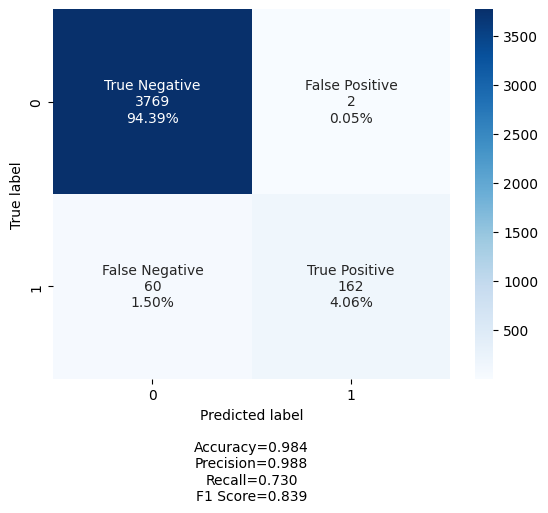

In [42]:
cm = confusion_matrix(y_test, y_pred)
labels = ['True Negative','False Positive','False Negative','True Positive']
make_confusion_matrix(cm,group_names=labels,cmap='Blues')

# **Neural Network Model Building**

In [43]:
#Defining the columns of the dataframe which are nothing but the hyper parameters and the metrics.
columns0 = ["# hidden layers","# neurons - hidden layer","activation function - hidden layer","# epochs","batch size","optimizer","learning rate, momentum","weight initializer","regularization","train loss","validation loss","train accuracy","validation accuracy","time (secs)"]
#Creating a pandas dataframe.
results0 = pd.DataFrame(columns=columns0)

#Defining the columns of the dataframe which are nothing but the hyper parameters and the metrics.
columns2 = ["# hidden layers","# neurons - hidden layer","activation function - hidden layer ","# Class_weights","# Dropout","# epochs","batch size","optimizer","learning rate, momentum","weight initializer","regularization","train loss","validation loss","train accuracy","validation accuracy","time (secs)"]
results2 = pd.DataFrame(columns=columns2)

In [44]:
X_train = np.array(X_train)
y_train = np.array(y_train)
X_val = np.array(X_val)
y_val = np.array(y_val)

In [45]:
from sklearn.utils.class_weight import compute_class_weight

y = df['Target']

# 4. Compute class weights
classes = np.unique(y)
class_weights = compute_class_weight(class_weight='balanced', classes=classes, y=y)

# 5. Convert to dictionary
class_weight = dict(zip(classes, class_weights))
print("Class weights:", class_weight)

Class weights: {np.int64(0): np.float64(0.5294367243025353), np.int64(1): np.float64(8.992792792792793)}


* Class weights help model in neural networks  to handle imbalanced datasets by penalizing misclassification of minority classes more heavily.

In [46]:
batch_size = 64
epochs = 50
num_classes = 2

In [47]:
# convert class vectors to binary class matrices
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)
y_val = keras.utils.to_categorical(y_val, num_classes)

* Converts each class label into a binary vector.
* Essential for training models with categorical_crossentropy loss.

# **Model Performance Improvement and Final Model Selection**

here I going to use combinations of different methods mentioned below to improve the model performance

  * More hidden layers
  - Different optimizers
  - Dropout
  - Class Weights


## **Let check the performence of the different models using optimizer as SGD**

### **Model with single hidden layer with 64 neurons and activation function as RELU**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,754 (10.76 KB)

 Trainable params: 2,754 (10.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9325 - loss: 0.2255 - val_accuracy: 0.9730 - val_loss: 0.1147
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9738 - loss: 0.1035 - val_accuracy: 0.9777 - val_loss: 0.0941
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9781 - loss: 0.0879 - val_accuracy: 0.9797 - val_loss: 0.0849
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9816 - loss: 0.0801 - val_accuracy: 0.9807 - val_loss: 0.0795
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9837 - loss: 0.0753 - val_accuracy: 0.9830 - val_loss: 0.0758
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9847 - loss: 0.0719 - val_accuracy: 0.9835 - val_loss: 0.0731
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9856 - loss: 0.0692 - val_accuracy: 0.9840 - val_loss: 0.0709
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9863 - loss: 0.0671 - val_accuracy: 0.

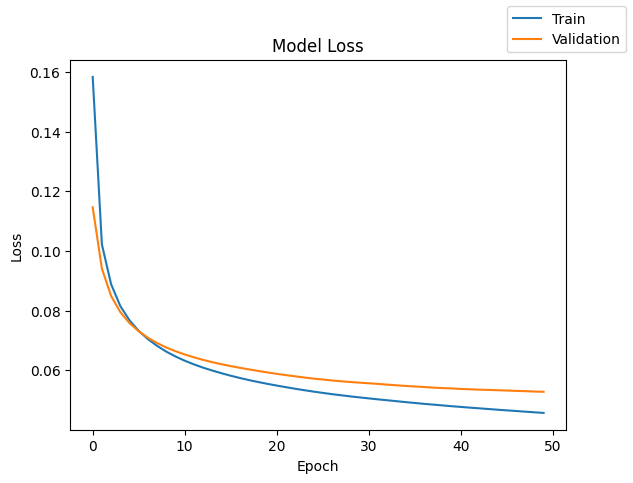

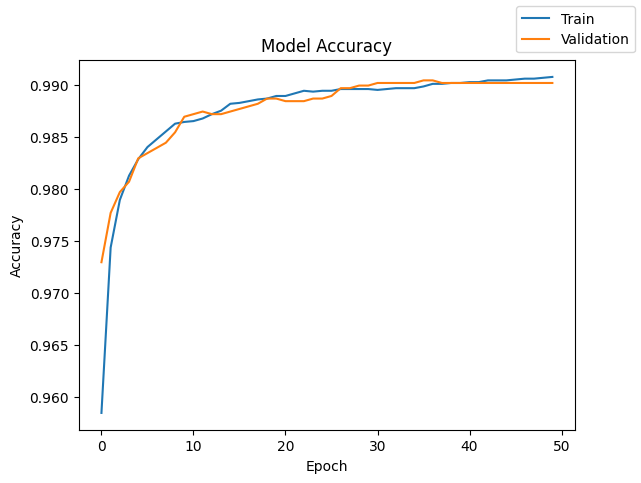

In [48]:
#Initializing the neural network
model_1 = Sequential()
model_1.add(Dense(64,activation="relu",input_dim = X_train.shape[1]))
model_1.add(Dense(num_classes,activation = 'softmax'))

model_1.summary()

model_1.compile(loss="categorical_crossentropy", optimizer = keras.optimizers.SGD(), metrics=["accuracy"])

start = time.time()
history = model_1.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs)
end=time.time()

print("Time taken in seconds ",end-start)

plot(history,'loss')

plot(history,'accuracy')

results0.loc[0] = [1,64,"relu",50,64,"sgd",[0.001, "-"],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model_1" has single hidden layer with 64 neurons,activation function as RELU  and optimizer as Stochastic Gradient Descent (SGD) has Validation accuracy at 99% percent
* The "model_1" gives validation accuracy at 99% without any parameter like momentum,Dropout,class_weight....etc.
* The "model_1" learns too much on training data so the "model_1" seems to be  a underfit model.
* The "model_1" has 16% percent loss at training data for first epoch and training loss has steep decrease after 10 epochs
* The "model_1" has 11% percent loss at valdation data for first epoch and valdation loss has steep decrease after 10 epochs
* Time taken by the "model_1" is 45.69s

**Let's check the model performence by add some momentum**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           130 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,754 (10.76 KB)

 Trainable params: 2,754 (10.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.6805 - loss: nan - val_accuracy: 0.9144 - val_loss: 0.2571
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.7527 - loss: nan - val_accuracy: 0.9664 - val_loss: 0.1436
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.7624 - loss: nan - val_accuracy: 0.8244 - val_loss: 0.4458
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.7458 - loss: nan - val_accuracy: 0.9464 - val_loss: 0.1953
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.7573 - loss: nan - val_accuracy: 0.9669 - val_loss: 0.1535
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7599 - loss: nan - val_accuracy: 0.9780 - val_loss: 0.1229
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7700 - loss: nan - val_accuracy: 0.9609 - val_loss: 0.1777
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.7574 - loss: nan - val_accuracy: 0.9547 - val_loss: 0.1

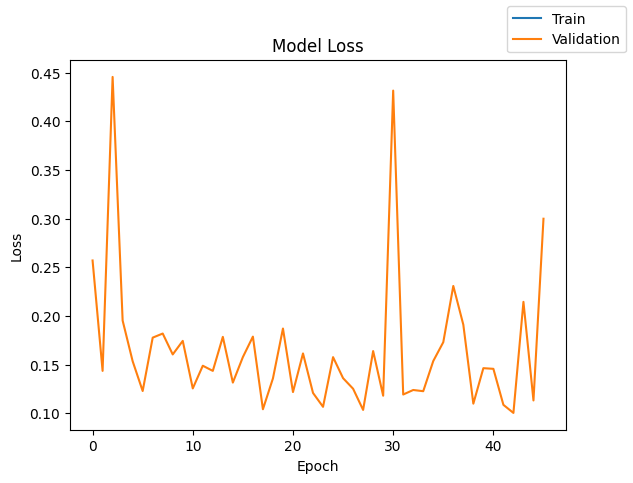

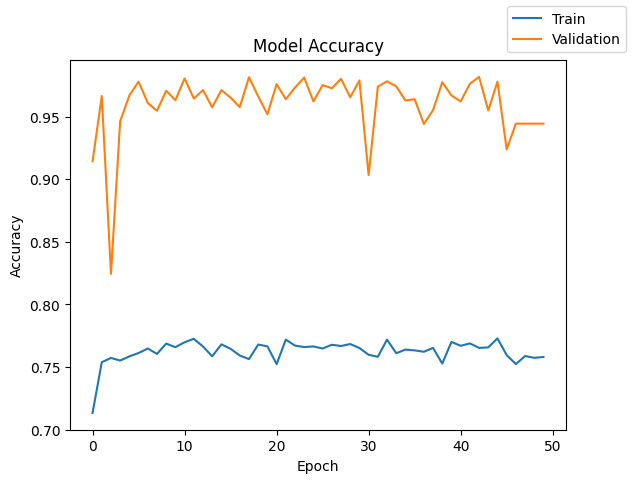

In [49]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model_1 = Sequential()
model_1.add(Dense(64,activation="relu",input_dim = X_train.shape[1]))
model_1.add(Dense(num_classes,activation = 'softmax'))
model_1.add(Dropout(0.3))
model_1.summary()

mom = 0.9    # defining the momentum value to be used
model_1.compile(loss="categorical_crossentropy", optimizer=keras.optimizers.SGD(momentum=mom), metrics=["accuracy"])

start = time.time()
history = model_1.fit(X_train, y_train, validation_data=(X_val, y_val),
                      batch_size=batch_size, epochs=epochs, class_weight=class_weight)

end=time.time()

print("Time taken in seconds ",end-start)

plot(history,'loss')

plot(history,'accuracy')

results2.loc[0] = [1,64,"relu","Initialized",0.3,50,64,"sgd with momentum,Dropout and class_weight",[0.001,0.9],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model_1" has single hidden layer with 64 neurons,activation function as RELU  and optimizer as Stochastic Gradient Descent (SGD) has Validation accuracy at 99% percent
* The "model_1" gives training accuracy at 75% without any parameter like Dropout,class_weight....etc.
* The "model_1" gives validation accuracy at 99% without any parameter like Dropout,class_weight....etc.
* The "model_1" with momentum has maximum of 45% percent loss at valdation data for first epoch and valdation loss has steep decrease after 10 epochs
* The time taken by the "model_1" is 47.61s


### **Model with 3 hidden layer with 128 neurons in each layer and activation functions as Relu, Tanh, Sigmoid**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         5,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,530 (150.51 KB)

 Trainable params: 38,530 (150.51 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9439 - loss: 0.2146 - val_accuracy: 0.9444 - val_loss: 0.1913
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9439 - loss: 0.1869 - val_accuracy: 0.9444 - val_loss: 0.1706
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9439 - loss: 0.1661 - val_accuracy: 0.9444 - val_loss: 0.1520
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9448 - loss: 0.1477 - val_accuracy: 0.9502 - val_loss: 0.1363
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9512 - loss: 0.1323 - val_accuracy: 0.9592 - val_loss: 0.1231
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9582 - loss: 0.1194 - val_accuracy: 0.9642 - val_loss: 0.1118
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9649 - loss: 0.1083 - val_accuracy: 0.9682 - val_loss: 0.1022
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9687 - loss: 0.0990 - val_accuracy: 0.

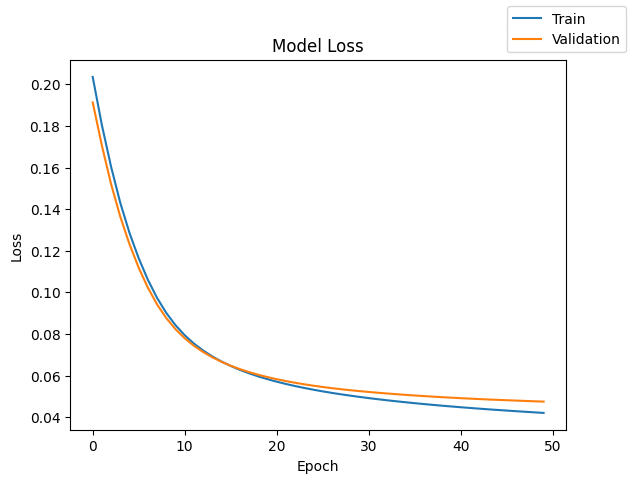

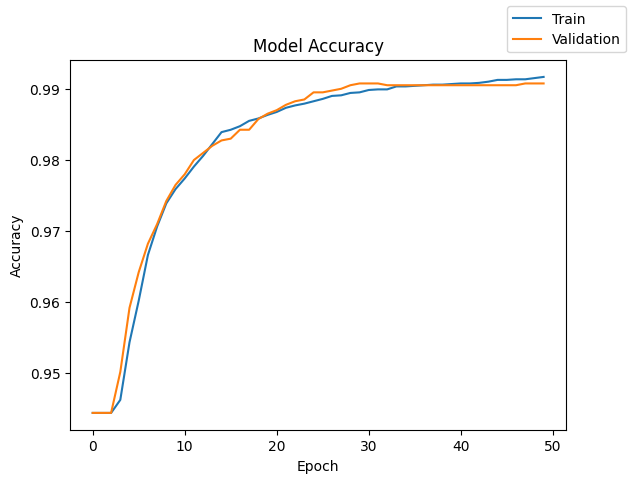

In [50]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model1 = Sequential()
model1.add(Dense(128,activation="relu",input_dim = X_train.shape[1]))
model1.add(Dense(128,activation="tanh"))
model1.add(Dense(128,activation="sigmoid"))
model1.add(Dense(num_classes,activation = 'softmax'))

model1.summary()

model1.compile(loss="categorical_crossentropy", optimizer = keras.optimizers.SGD(), metrics=["accuracy"])

start = time.time()
history = model1.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs)
end=time.time()

print("Time taken in seconds ",end-start)

plot(history,'loss')

plot(history,'accuracy')

results0.loc[1] = [3,[128,128,128], ["relu","tanh","sigmoid"] ,50,64,"sgd",[0.001,"-"],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model1" has 3 hidden layer with 128 neurons in each layer,activation function as RELU for first layer and Tanh for second layer and Sigmoid for third layer with optimizer as Stochastic Gradient Descent (SGD)
* The "model1" gives validation accuracy at 99% without any parameter like momentum,Dropout,class_weight....etc.
* The "model1" learns too much on training data so the "model1" seems to be a underfit model.
* The "model1" has 20% percent loss at training data for first epoch and training loss has steep decrease after 10 epochs
* The "model1" has 19% percent loss at valdation data for first epoch and valdation loss has steep decrease after 10 epochs
* Time taken by the "model1" is 23.86s

**Let's check the model performance by adding Dropout, Momentum and Class_weight**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         5,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           258 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,530 (150.51 KB)

 Trainable params: 38,530 (150.51 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6058 - loss: nan - val_accuracy: 0.8182 - val_loss: 0.4740
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7302 - loss: nan - val_accuracy: 0.8893 - val_loss: 0.3189
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7402 - loss: nan - val_accuracy: 0.9249 - val_loss: 0.2323
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7495 - loss: nan - val_accuracy: 0.9236 - val_loss: 0.2236
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7426 - loss: nan - val_accuracy: 0.8996 - val_loss: 0.2942
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7631 - loss: nan - val_accuracy: 0.9509 - val_loss: 0.1937
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7572 - loss: nan - val_accuracy: 0.9594 - val_loss: 0.1631
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7626 - loss: nan - val_accuracy: 0.9286 - val_loss: 0.2452


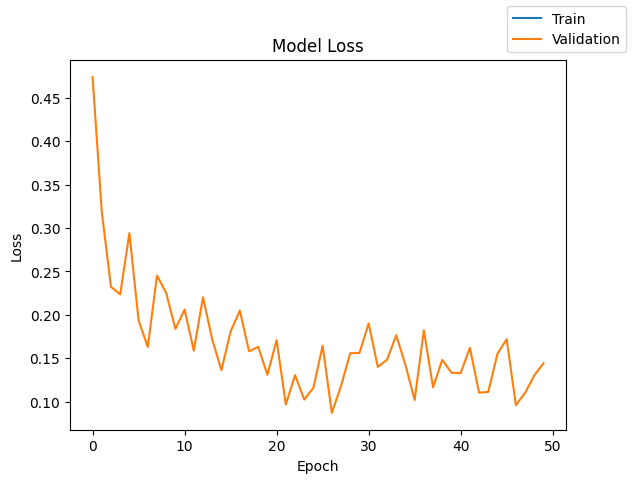

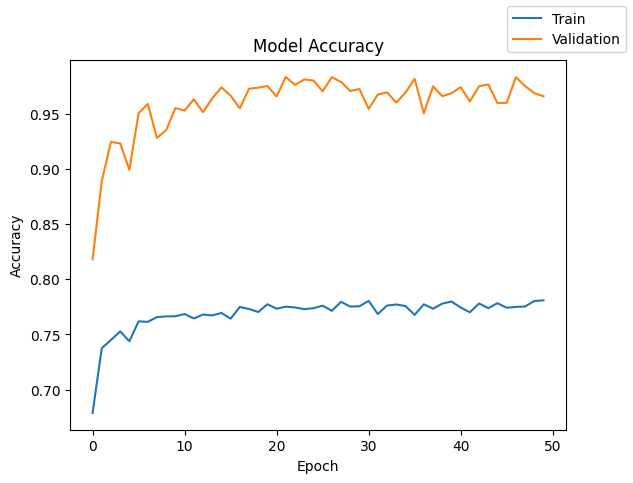

In [51]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model1 = Sequential()
model1.add(Dense(128,activation="relu",input_dim = X_train.shape[1]))
model1.add(Dense(128,activation="tanh"))
model1.add(Dense(128,activation="sigmoid"))
model1.add(Dense(num_classes,activation = 'softmax'))
model1.add(Dropout(0.3))
model1.summary()
mom= 0.5
model1.compile(loss="categorical_crossentropy", optimizer = keras.optimizers.SGD(momentum=mom), metrics=["accuracy"])

start = time.time()
history = model1.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs,class_weight=class_weight)
end=time.time()

print("Time taken in seconds ",end-start)

plot(history,'loss')

plot(history,'accuracy')

results2.loc[1] = [3,[128,128,128], ["relu","tanh","sigmoid"],"Initialized",0.3,50,64,"sgd with momentum,Dropout and class_weight",[0.001,0.5],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model1" has 3 hidden layer with 128 neurons in each layer,activation function as RELU for first layer and Tanh for second layer and Sigmoid for third layer with optimizer as Stochastic Gradient Descent (SGD)
* The "model1" gives validation accuracy at 96% without any parameter like Dropout,class_weight....etc.
* The "model1" gives Training accuracy at 76% without any parameter like Dropout,class_weight....etc.
* The "model1" has morethan 45% percent loss at valdation data for first epoch and valdation loss has steep decrease after 10 epochs
* Time taken by the "model1" is 24.08s

### **Model with 2 hidden layers with 64 neurons in one layer  & 128 neurons in another layer, having activation functions as Relu for both hidden layers**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,202 (43.76 KB)

 Trainable params: 11,202 (43.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7550 - loss: nan - val_accuracy: 0.9444 - val_loss: nan
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7450 - loss: nan - val_accuracy: 0.9444 - val_loss: nan
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7540 - loss: nan - val_accuracy: 0.9444 - val_loss: nan
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7553 - loss: nan - val_accuracy: 0.9444 - val_loss: nan
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7553 - loss: nan - val_accuracy: 0.9444 - val_loss: nan
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7546 - loss: nan - val_accuracy: 0.9444 - val_loss: nan
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7589 - loss: nan - val_accuracy: 0.9444 - val_loss: nan
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7678 - loss: nan - val_accuracy: 0.9444 - val_loss: nan
Epoch 9/50
188/188 ━━━━━

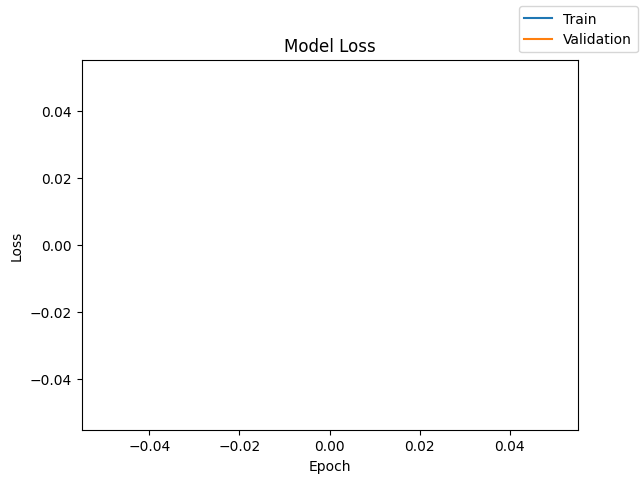

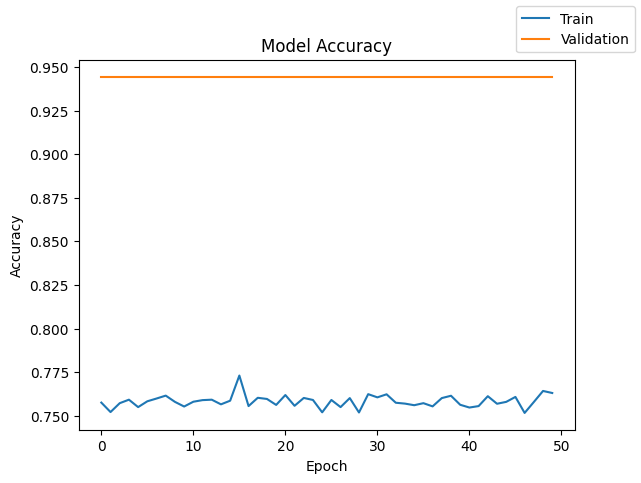

In [52]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model2 = Sequential()
model2.add(Dense(64,activation="relu",input_dim = X_train.shape[1]))
model2.add(Dense(128,activation="relu"))
model2.add(Dense(num_classes,activation = 'softmax'))

model2.summary()

model2.compile(loss="categorical_crossentropy", optimizer=keras.optimizers.SGD(), metrics=["accuracy"])

start = time.time()
history = model_1.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs)
end=time.time()

plot(history,'loss')

plot(history,'accuracy')

print("Time taken in seconds ",end-start)

results0.loc[2] = [2,[64,128],["relu","relu"],50,64,"sgd",[0.001,"-"],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model2" has 2 hidden layer with 64 neurons in one layer and 128 neurons in another layer, having activation function as RELU both hidden  and optimizer as Stochastic Gradient Descent (SGD)
* The "model2" has Validation accuracy at 94% percent
* The "model2" gives validation accuracy at 94% without any parameter like momentum,Dropout,class_weight....etc.
* The "model2" gives training accuracy at 76% without any parameter like momentum,Dropout,class_weight....etc.
* Time taken by the "model2" is 20.61s

**Let's check the model performance by adding Dropout, Momentum and Class_weight**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,202 (43.76 KB)

 Trainable params: 11,202 (43.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.6587 - loss: nan - val_accuracy: 0.9241 - val_loss: 0.2463
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7422 - loss: nan - val_accuracy: 0.8417 - val_loss: 0.3871
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7396 - loss: nan - val_accuracy: 0.9592 - val_loss: 0.1743
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7664 - loss: nan - val_accuracy: 0.8901 - val_loss: 0.3244
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7493 - loss: nan - val_accuracy: 0.9562 - val_loss: 0.1608
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7578 - loss: nan - val_accuracy: 0.9221 - val_loss: 0.2392
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7682 - loss: nan - val_accuracy: 0.9740 - val_loss: 0.1143
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7697 - loss: nan - val_accuracy: 0.9046 - val_loss: 0.2860


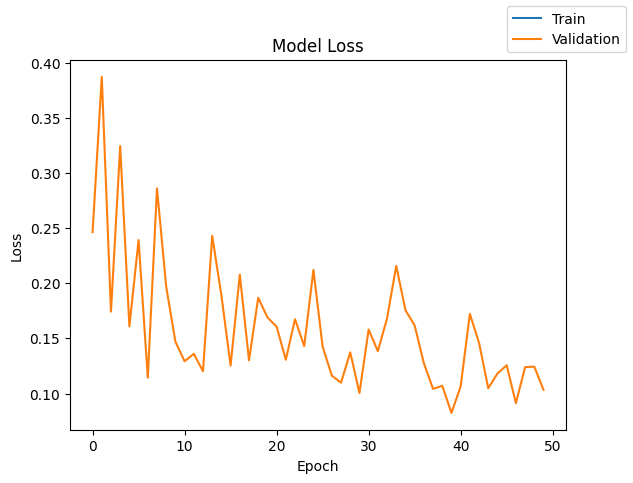

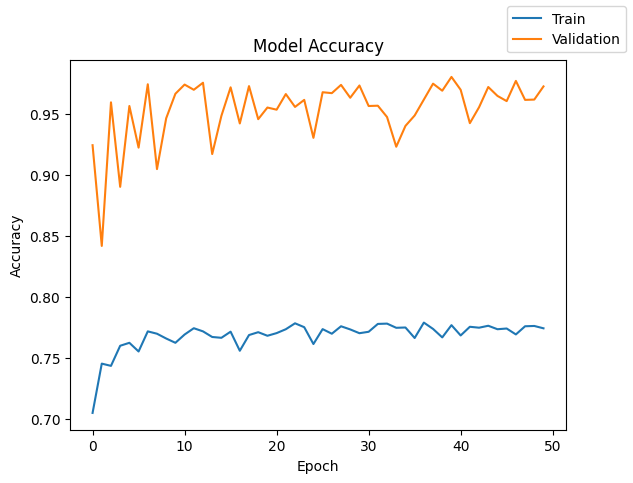

In [53]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model2 = Sequential()
model2.add(Dense(64,activation="relu",input_dim = X_train.shape[1]))
model2.add(Dense(128,activation="relu"))
model2.add(Dense(num_classes,activation = 'softmax'))
model2.add(Dropout(0.3))
model2.summary()
mom = 0.5
model2.compile(loss="categorical_crossentropy", optimizer=keras.optimizers.SGD(momentum = mom), metrics=["accuracy"])

start = time.time()
history = model2.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs,class_weight=class_weight)
end=time.time()

plot(history,'loss')

plot(history,'accuracy')

print("Time taken in seconds ",end-start)

results2.loc[2] = [2,[64,128],["relu","relu"],"Initialized",0.3,50,64,"sgd with momentum,Dropout and class_weight",[0.001,"0.5"],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model2" has 2 hidden layer with 64 neurons in one layer and 128 neurons in another layer, having activation function as RELU both hidden  and optimizer as Stochastic Gradient Descent (SGD)
* The "model2" has Validation accuracy at 97% percent
* The "model2" gives validation accuracy at 97% with parameter like momentum,Dropout,class_weight....etc.
* The "model2" gives training accuracy at 76% with parameter like momentum,Dropout,class_weight....etc.
* Time taken by the "model2" is 32.12s

### **Model with 2 hidden layers with 64 neurons in one layer & 128 neurons in another layer, having activation functions as Tanh for both hidden layers**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,202 (43.76 KB)

 Trainable params: 11,202 (43.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8780 - loss: 0.3014 - val_accuracy: 0.9684 - val_loss: 0.1260
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9650 - loss: 0.1256 - val_accuracy: 0.9712 - val_loss: 0.1073
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9691 - loss: 0.1079 - val_accuracy: 0.9725 - val_loss: 0.0994
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9716 - loss: 0.0983 - val_accuracy: 0.9732 - val_loss: 0.0942
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9734 - loss: 0.0914 - val_accuracy: 0.9752 - val_loss: 0.0902
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9749 - loss: 0.0859 - val_accuracy: 0.9757 - val_loss: 0.0869
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9774 - loss: 0.0814 - val_accuracy: 0.9775 - val_loss: 0.0842
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9791 - loss: 0.0777 - val_accuracy: 0.

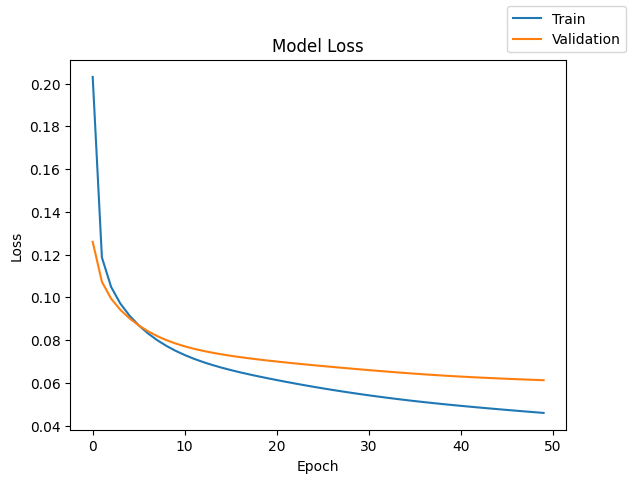

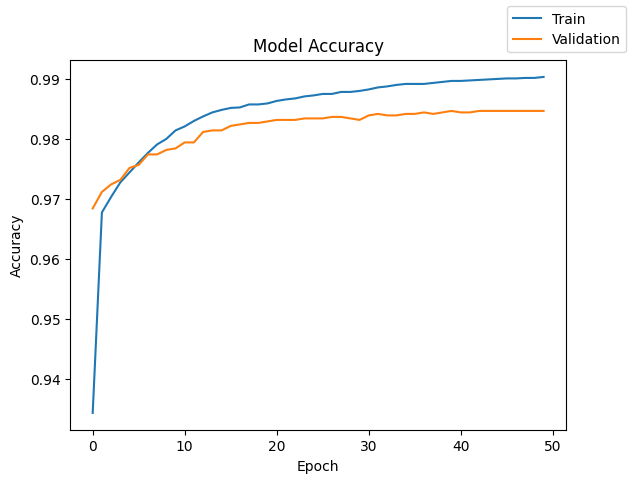

In [54]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model3 = Sequential()
model3.add(Dense(64,activation="tanh",input_dim = X_train.shape[1]))
model3.add(Dense(128,activation="tanh"))
model3.add(Dense(num_classes,activation = 'softmax'))

model3.summary()
model3.compile(loss="categorical_crossentropy", optimizer=keras.optimizers.SGD(), metrics=["accuracy"])

start = time.time()
history = model3.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs)
end=time.time()

plot(history,'loss')

plot(history,'accuracy')

print("Time taken in seconds ",end-start)

results0.loc[3] = [2,[64,128],["tanh","tanh"],50,64,"sgd",[0.001,"-"],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model3" has 2 hidden layer with 64 neurons in one layer and 128 neurons in another layer, having activation function as Tanh both hidden  and optimizer as Stochastic Gradient Descent (SGD)
* The "model3" has Validation accuracy at 98.65% percent
* The "model3" gives validation accuracy at 94% without any parameter like momentum,Dropout,class_weight....etc.
* The "model3" gives training accuracy at 99% without any parameter like momentum,Dropout,class_weight....etc.
* The "model3" seems to be underfit model
* The "model3" has loss near to 15% percent of data in training and in validation the "model3" has loss near to 13% percent
* Time taken by the "model3" is 21.95s


**Let's check the model performance by adding Dropout, Momentum and Class_weight**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,202 (43.76 KB)

 Trainable params: 11,202 (43.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7045 - loss: nan - val_accuracy: 0.8921 - val_loss: 0.2784
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7346 - loss: nan - val_accuracy: 0.9121 - val_loss: 0.2646
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7458 - loss: nan - val_accuracy: 0.8986 - val_loss: 0.2988
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7449 - loss: nan - val_accuracy: 0.9136 - val_loss: 0.2657
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7514 - loss: nan - val_accuracy: 0.9354 - val_loss: 0.2040
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7488 - loss: nan - val_accuracy: 0.9459 - val_loss: 0.1843
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7593 - loss: nan - val_accuracy: 0.9492 - val_loss: 0.1767
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7633 - loss: nan - val_accuracy: 0.9469 - val_loss: 0.1777


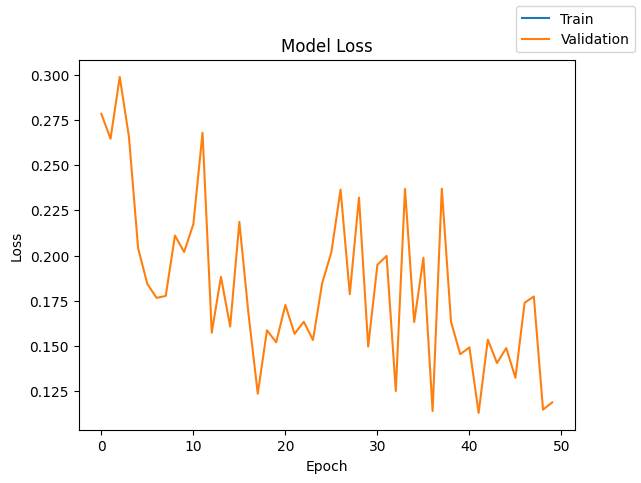

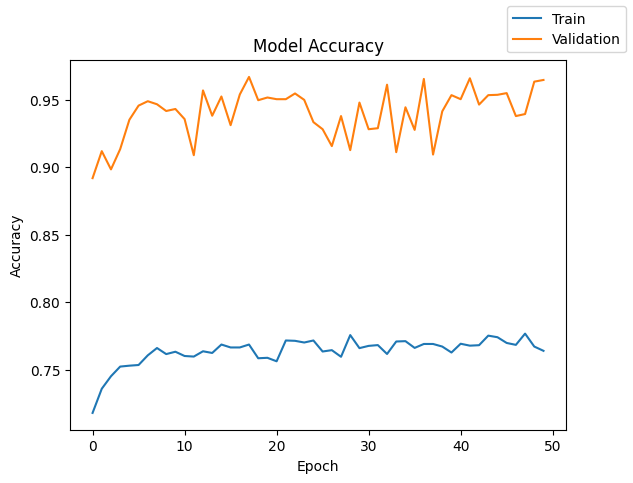

In [55]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model3 = Sequential()
model3.add(Dense(64,activation="tanh",input_dim = X_train.shape[1]))
model3.add(Dense(128,activation="tanh"))
model3.add(Dense(num_classes,activation = 'softmax'))
model3.add(Dropout(0.3))

model3.summary()
mom = 0.5
model3.compile(loss="categorical_crossentropy", optimizer=keras.optimizers.SGD(momentum = mom), metrics=["accuracy"])

start = time.time()
history = model3.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs,class_weight=class_weight)
end=time.time()

plot(history,'loss')

plot(history,'accuracy')

print("Time taken in seconds ",end-start)

results2.loc[3] = [2,[64,128],["tanh","tanh"],"Initialized",0.3,50,64,"sgd with momentum,Dropout and momentum",[0.001,0.5],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model3" has 2 hidden layer with 64 neurons in one layer and 128 neurons in another layer, having activation function as RELU both hidden  and optimizer as Stochastic Gradient Descent (SGD)
* The "model3" has Validation accuracy at 96% percent
* The "model3" gives validation accuracy at 97% with parameter like momentum,Dropout,class_weight....etc.
* The "model3" gives training accuracy at 76% with parameter like momentum,Dropout,class_weight....etc.
* The "model3" has loss of 30% percent data on validation set
* Time taken by the "model3" is --s


### **Model with 2 hidden layers with 64 neurons in one layer & 128 neurons in another layer, having activation functions as Sigmoid for both hidden layers**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,202 (43.76 KB)

 Trainable params: 11,202 (43.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9439 - loss: 0.2148 - val_accuracy: 0.9444 - val_loss: 0.2103
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9439 - loss: 0.2103 - val_accuracy: 0.9444 - val_loss: 0.2062
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9439 - loss: 0.2061 - val_accuracy: 0.9444 - val_loss: 0.2022
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9439 - loss: 0.2018 - val_accuracy: 0.9444 - val_loss: 0.1983
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9439 - loss: 0.1976 - val_accuracy: 0.9444 - val_loss: 0.1942
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9439 - loss: 0.1932 - val_accuracy: 0.9444 - val_loss: 0.1900
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9439 - loss: 0.1888 - val_accuracy: 0.9444 - val_loss: 0.1857
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9439 - loss: 0.1842 - val_accuracy: 0.

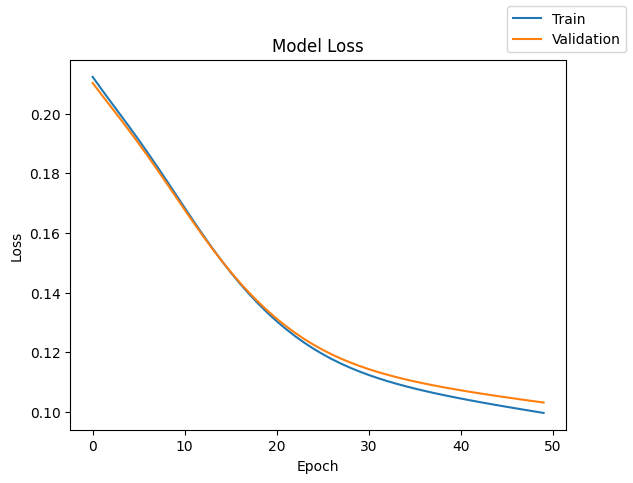

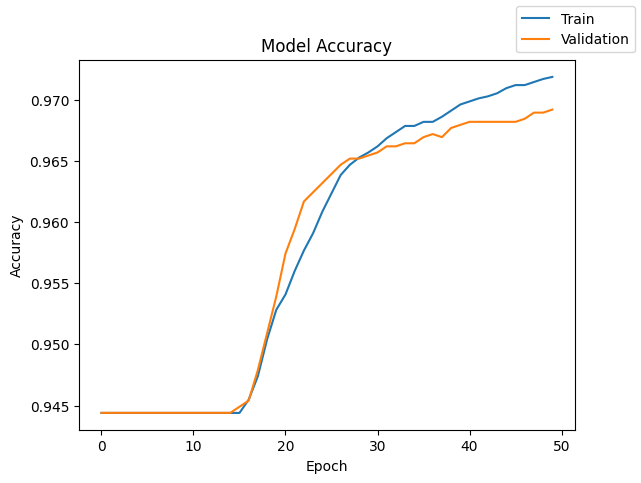

In [56]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model4 = Sequential()
model4.add(Dense(64,activation="sigmoid",input_dim = X_train.shape[1]))
model4.add(Dense(128,activation="sigmoid"))
model4.add(Dense(num_classes,activation = 'softmax'))

model4.summary()
model4.compile(loss="categorical_crossentropy", optimizer=keras.optimizers.SGD(), metrics=["accuracy"])

start = time.time()
history = model4.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs)
end = time.time()

plot(history,'loss')

plot(history,'accuracy')

print("Time taken in seconds ",end-start)

results0.loc[4] = [2,[64,128],["sigmoid","sigmoid"],50,64,"sgd",[0.001,"-"],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model4" has 2 hidden layer with 64 neurons in one layer and 128 neurons in another layer, having activation function as Sigmoid for both hidden layers and optimizer as Stochastic Gradient Descent (SGD)
* The "model4" has Validation accuracy at 96.92% percent
* The "model4" gives validation accuracy at 96.92% without any parameter like momentum,Dropout,class_weight....etc.
* The "model4" gives training accuracy at 97% without any parameter like momentum,Dropout,class_weight....etc.
* The "model4" seems to be underfit model
* The "model4" has loss more to 20% percent of data in training and in validation the "model4" has loss near to 20% percent
* Time taken by the "model4" is --s


**Let's check the model performance by adding Dropout, Momentum and Class_weight**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,202 (43.76 KB)

 Trainable params: 11,202 (43.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5661 - loss: nan - val_accuracy: 0.5828 - val_loss: 0.6874
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6817 - loss: nan - val_accuracy: 0.7526 - val_loss: 0.5809
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6938 - loss: nan - val_accuracy: 0.7658 - val_loss: 0.5441
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6939 - loss: nan - val_accuracy: 0.8943 - val_loss: 0.3265
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7031 - loss: nan - val_accuracy: 0.8800 - val_loss: 0.3349
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7234 - loss: nan - val_accuracy: 0.8412 - val_loss: 0.3889
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7156 - loss: nan - val_accuracy: 0.8375 - val_loss: 0.3929
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7162 - loss: nan - val_accuracy: 0.8257 - val_loss: 0.4163


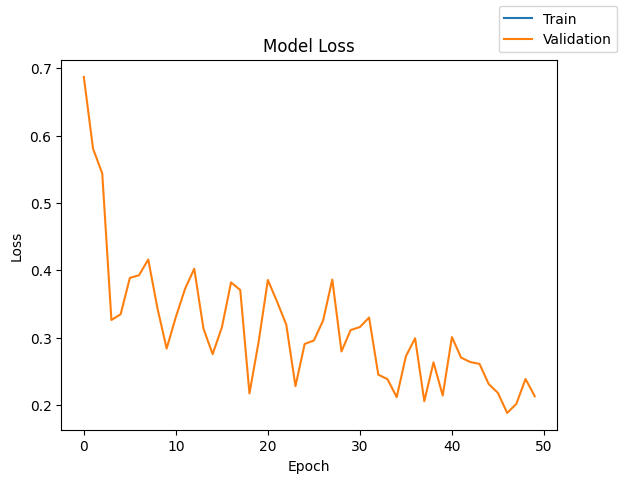

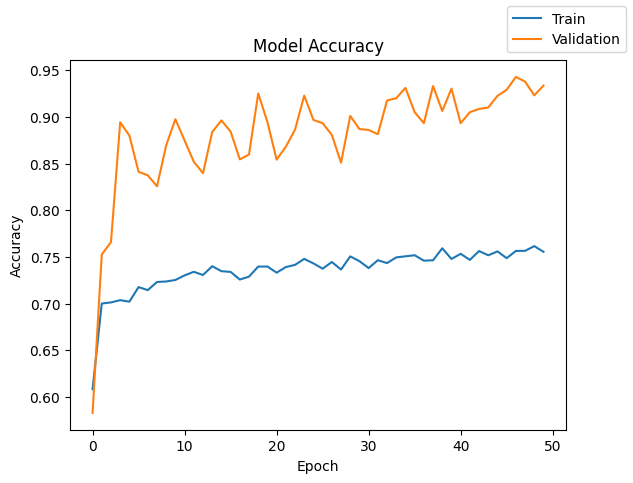

In [57]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model4 = Sequential()
model4.add(Dense(64,activation="sigmoid",input_dim = X_train.shape[1]))
model4.add(Dense(128,activation="sigmoid"))
model4.add(Dense(num_classes,activation = 'softmax'))
model4.add(Dropout(0.3))
model4.summary()

mom = 0.5
model4.compile(loss="categorical_crossentropy", optimizer=keras.optimizers.SGD(momentum = 0.5), metrics=["accuracy"])

start = time.time()
history = model4.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs,class_weight=class_weight)
end = time.time()

plot(history,'loss')

plot(history,'accuracy')

print("Time taken in seconds ",end-start)

results2.loc[4] = [2,[64,128],["sigmoid","sigmoid"],"Initialized",0.3,50,64,"sgd with momentum, Dropout and class_weight",[0.001,0.5],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model4" has 2 hidden layer with 64 neurons in one layer and 128 neurons in another layer, having activation function as Sigmoid for both hidden layers and optimizer as Stochastic Gradient Descent (SGD)
* The "model4" has Validation accuracy at 93% percent
* The "model4" gives validation accuracy at 93% with parameter like momentum,Dropout,class_weight....etc.
* The "model4" gives training accuracy at 75% with parameter like momentum,Dropout,class_weight....etc.
* The "model4" has loss 70% percent in validation set at first epoch and the loss has steep decrese after 20 Epochs
* Time taken by the "model4" is ---s


### **Model with 2 hidden layers with 64 neurons in one layer & 128 neurons in another layer, having activation functions as RELU for first hidden layers and activation function as Tanh for second hidden layer**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,202 (43.76 KB)

 Trainable params: 11,202 (43.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9400 - loss: 0.1819 - val_accuracy: 0.9627 - val_loss: 0.1101
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9663 - loss: 0.1026 - val_accuracy: 0.9742 - val_loss: 0.0902
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9738 - loss: 0.0860 - val_accuracy: 0.9780 - val_loss: 0.0801
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9784 - loss: 0.0767 - val_accuracy: 0.9812 - val_loss: 0.0739
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9812 - loss: 0.0707 - val_accuracy: 0.9827 - val_loss: 0.0696
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9833 - loss: 0.0664 - val_accuracy: 0.9842 - val_loss: 0.0665
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9849 - loss: 0.0631 - val_accuracy: 0.9860 - val_loss: 0.0640
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9855 - loss: 0.0605 - val_accuracy: 0.

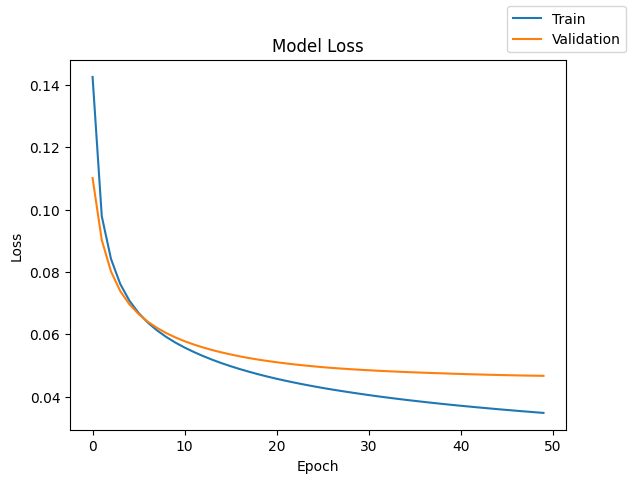

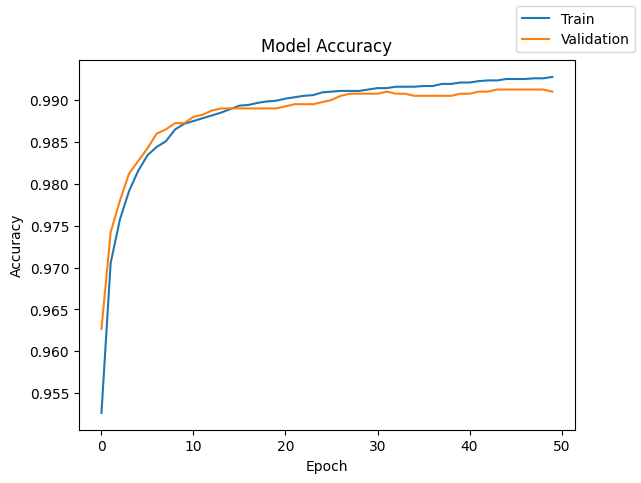

In [58]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model5 = Sequential()
model5.add(Dense(64,activation="relu",input_dim = X_train.shape[1]))
model5.add(Dense(128,activation="tanh"))
model5.add(Dense(num_classes,activation = 'softmax'))

model5.summary()
model5.compile(loss="categorical_crossentropy", optimizer = keras.optimizers.SGD(), metrics=["accuracy"])

start = time.time()
history = model5.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs)
end=time.time()

plot(history,'loss')

plot(history,'accuracy')

print("Time taken in seconds ",end-start)

results0.loc[5] = [2,[64,128],["relu","tanh"],50,64,"sgd",[0.001,"-"],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model5" has 2 hidden layer with 64 neurons in one layer and 128 neurons in another layer, having activation function as Relu for first hidden layer and Tanh for the second hidden layer and optimizer as Stochastic Gradient Descent (SGD)
* The "model5" has Validation accuracy at 99% percent
* The "model5" gives validation accuracy at 99% without any parameter like momentum,Dropout,class_weight....etc.
* The "model5" gives training accuracy at 99% without any parameter like momentum,Dropout,class_weight....etc.
* The "model5" seems to be underfit model
* The "model5" has loss near to 15% percent of data in training and in validation the "model5" has loss near to 11% percent
* Time taken by the "model5" is ----s


**Let's check the model performance by adding Dropout, Momentum and Class_weight**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,202 (43.76 KB)

 Trainable params: 11,202 (43.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.7103 - loss: nan - val_accuracy: 0.8562 - val_loss: 0.3357
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7448 - loss: nan - val_accuracy: 0.9201 - val_loss: 0.2288
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7612 - loss: nan - val_accuracy: 0.9584 - val_loss: 0.1492
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7641 - loss: nan - val_accuracy: 0.9201 - val_loss: 0.2598
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7752 - loss: nan - val_accuracy: 0.8926 - val_loss: 0.3081
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7558 - loss: nan - val_accuracy: 0.9492 - val_loss: 0.1972
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7696 - loss: nan - val_accuracy: 0.9732 - val_loss: 0.1184
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7610 - loss: nan - val_accuracy: 0.9502 - val_loss: 0.1862

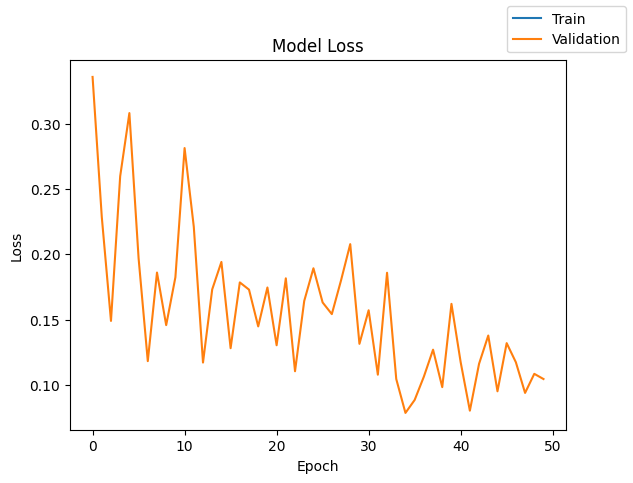

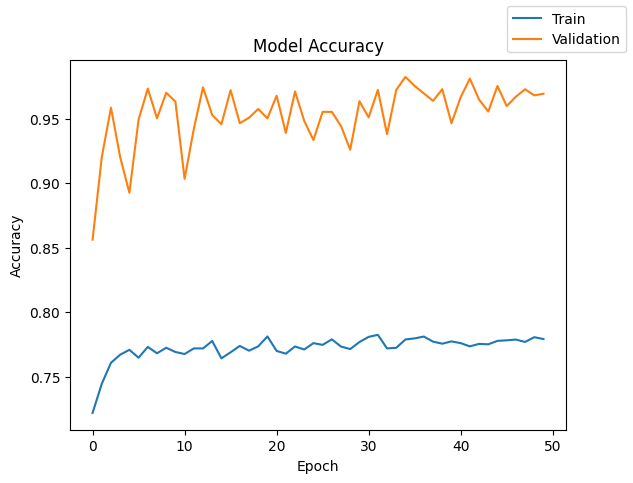

In [59]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model5 = Sequential()
model5.add(Dense(64,activation="relu",input_dim = X_train.shape[1]))
model5.add(Dense(128,activation="tanh"))
model5.add(Dense(num_classes,activation = 'softmax'))
model5.add(Dropout(0.3))

model5.summary()
mom = 0.5
model5.compile(loss="categorical_crossentropy", optimizer = keras.optimizers.SGD(momentum = mom), metrics=["accuracy"])

start = time.time()
history = model5.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs,class_weight=class_weight)
end=time.time()

plot(history,'loss')

plot(history,'accuracy')

print("Time taken in seconds ",end-start)

results2.loc[5] = [2,[64,128],["relu","tanh"],"Initialized",0.3,50,64,"sgd with momentum and Dropout",[0.001,0.5],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model5" has 2 hidden layer with 64 neurons in one layer and 128 neurons in another layer, having activation function as Relu for first hidden layer and Tanh for the second hidden layer and optimizer as Stochastic Gradient Descent (SGD)
* The "model5" has Validation accuracy at 96.94% percent
* The "model5" gives validation accuracy at 96.94% with parameter like momentum,Dropout,class_weight....etc.
* The "model5" gives training accuracy at 77% with parameter like momentum,Dropout,class_weight....etc.
* The "model5" has loss morethan 30% percent of data in validation
* Time taken by the "model5" is ----s


### **Model with 2 hidden layers with 64 neurons in one layer & 128 neurons in another layer, having activation functions as Tanh for first hidden layers and activation function as Sigmoid for second hidden layer**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,202 (43.76 KB)

 Trainable params: 11,202 (43.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8783 - loss: 0.3042 - val_accuracy: 0.9444 - val_loss: 0.1841
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9439 - loss: 0.1774 - val_accuracy: 0.9444 - val_loss: 0.1653
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9439 - loss: 0.1596 - val_accuracy: 0.9447 - val_loss: 0.1516
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9449 - loss: 0.1464 - val_accuracy: 0.9499 - val_loss: 0.1414
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9494 - loss: 0.1366 - val_accuracy: 0.9554 - val_loss: 0.1335
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9551 - loss: 0.1288 - val_accuracy: 0.9599 - val_loss: 0.1272
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9581 - loss: 0.1226 - val_accuracy: 0.9622 - val_loss: 0.1220
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9612 - loss: 0.1174 - val_accuracy: 0.

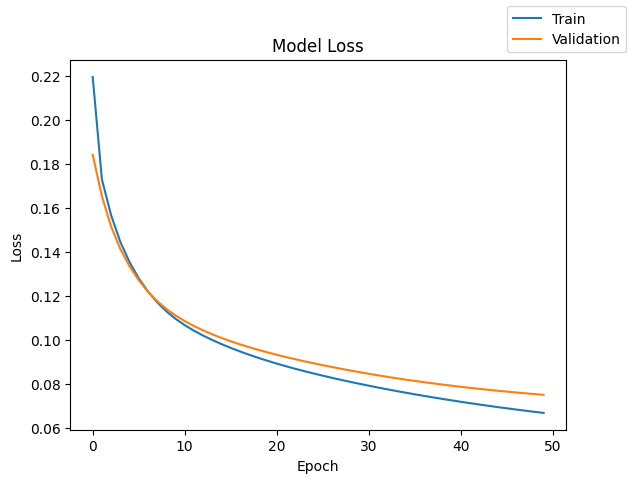

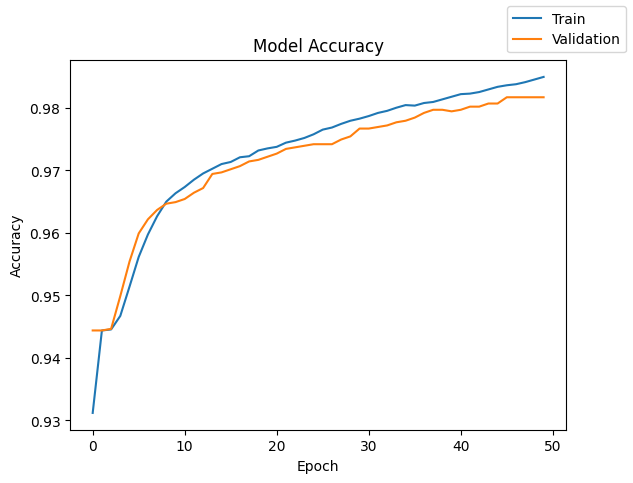

In [60]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model6 = Sequential()
model6.add(Dense(64,activation="tanh",input_dim = X_train.shape[1]))
model6.add(Dense(128,activation="sigmoid"))
model6.add(Dense(num_classes,activation = 'softmax'))

model6.summary()
model6.compile(loss="categorical_crossentropy", optimizer=keras.optimizers.SGD(), metrics=["accuracy"])

start = time.time()
history = model6.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs)
end=time.time()

plot(history,'loss')

plot(history,'accuracy')

print("Time taken in seconds ",end-start)

results0.loc[6] = [2,[64,128],["tanh","sigmoid"],50,64,"sgd",[0.001,"-"],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model6" has 2 hidden layer with 64 neurons in one layer and 128 neurons in another layer, having activation function as Tanh for first hidden layer and Sigmoid for the second hidden layer and optimizer as Stochastic Gradient Descent (SGD)
* The "model6" has Validation accuracy at 98% percent
* The "model6" gives validation accuracy at 98% without any parameter like momentum,Dropout,class_weight....etc.
The "model6" gives Training accuracy at 98% without any parameter like momentum,Dropout,class_weight....etc.
* The "model6" seems to be underfit model
* The "model6" has loss 22% percent of data in training and in validation the "model6" has loss of 18% percent
* Time taken by the "model6" is ----s


**Let's check the model performance by adding Dropout, Momentum and Class_weight**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,202 (43.76 KB)

 Trainable params: 11,202 (43.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.5501 - loss: nan - val_accuracy: 0.7839 - val_loss: 0.5145
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7039 - loss: nan - val_accuracy: 0.8442 - val_loss: 0.3790
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7185 - loss: nan - val_accuracy: 0.8440 - val_loss: 0.3831
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7272 - loss: nan - val_accuracy: 0.8795 - val_loss: 0.3102
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7251 - loss: nan - val_accuracy: 0.9006 - val_loss: 0.2680
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7288 - loss: nan - val_accuracy: 0.8653 - val_loss: 0.3370
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7397 - loss: nan - val_accuracy: 0.8953 - val_loss: 0.2793
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7344 - loss: nan - val_accuracy: 0.9051 - val_loss: 0.2606


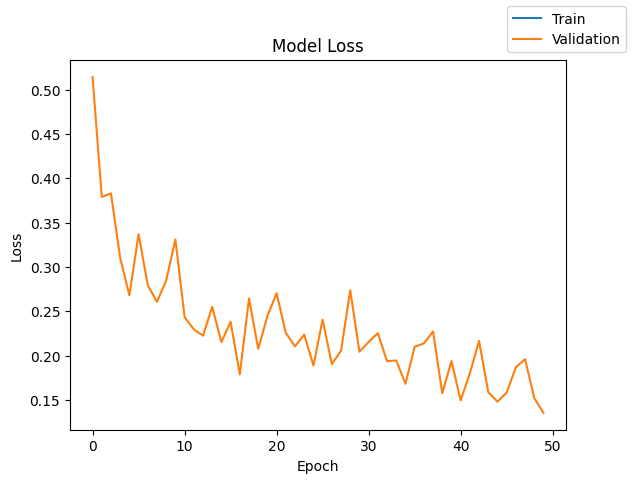

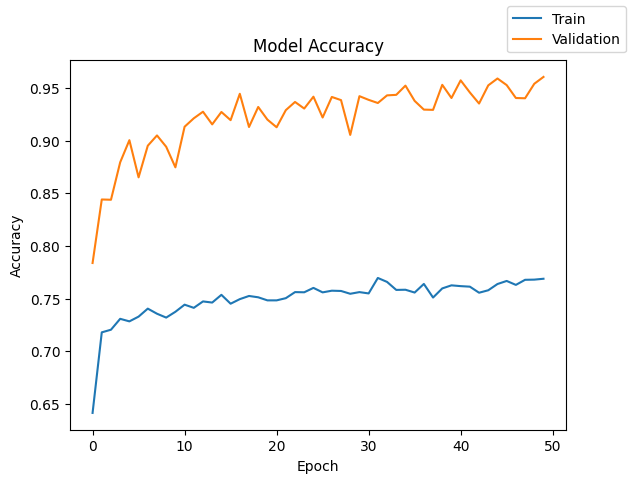

In [61]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model6 = Sequential()
model6.add(Dense(64,activation="tanh",input_dim = X_train.shape[1]))
model6.add(Dense(128,activation="sigmoid"))
model6.add(Dense(num_classes,activation = 'softmax'))
model6.add(Dropout(0.3))

model6.summary()
mom = 0.5
model6.compile(loss="categorical_crossentropy", optimizer=keras.optimizers.SGD(momentum=mom) , metrics=["accuracy"])

start = time.time()
history = model6.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs,class_weight=class_weight)
end=time.time()

plot(history,'loss')

plot(history,'accuracy')

results2.loc[6] = [2,[64,128],["tanh","sigmoid"],"Initialized",0.3,50,64,"sgd with momentum,Dropout and class_weight",[0.001,0.5],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model6" has 2 hidden layer with 64 neurons in one layer and 128 neurons in another layer, having activation function as Tanh for first hidden layer and Sigmoid for the second hidden layer and optimizer as Stochastic Gradient Descent (SGD)
* The "model6" has Validation accuracy at 96% percent
* The "model6" gives validation accuracy at 96% without any parameter like momentum,Dropout,class_weight....etc.
The "model6" gives Training accuracy at 77% without any parameter like momentum,Dropout,class_weight....etc.
* The "model6" has loss morethan 50% percent of data in validation
* Time taken by the "model6" is ----s

### **Model with 2 hidden layers with 64 neurons in one layer & 128 neurons in another layer, having activation functions as RELU for first hidden layers and activation function as Sigmoid for second hidden layer**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,202 (43.76 KB)

 Trainable params: 11,202 (43.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9344 - loss: 0.2493 - val_accuracy: 0.9444 - val_loss: 0.1789
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9439 - loss: 0.1727 - val_accuracy: 0.9444 - val_loss: 0.1562
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9449 - loss: 0.1514 - val_accuracy: 0.9477 - val_loss: 0.1403
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9499 - loss: 0.1364 - val_accuracy: 0.9544 - val_loss: 0.1282
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9560 - loss: 0.1251 - val_accuracy: 0.9579 - val_loss: 0.1185
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9604 - loss: 0.1159 - val_accuracy: 0.9639 - val_loss: 0.1105
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9631 - loss: 0.1083 - val_accuracy: 0.9654 - val_loss: 0.1038
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9670 - loss: 0.1018 - val_accuracy: 0.

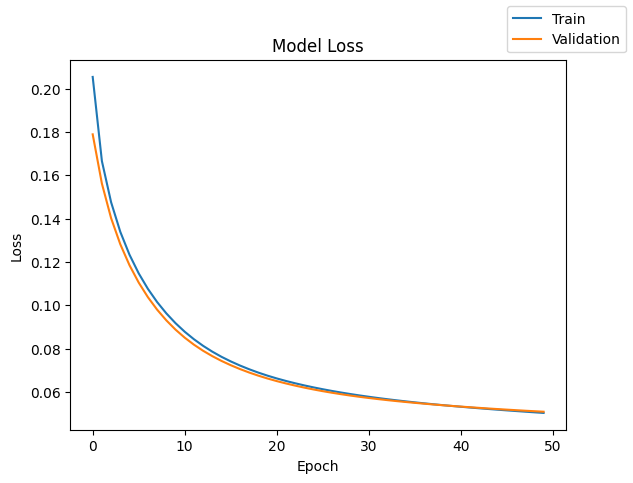

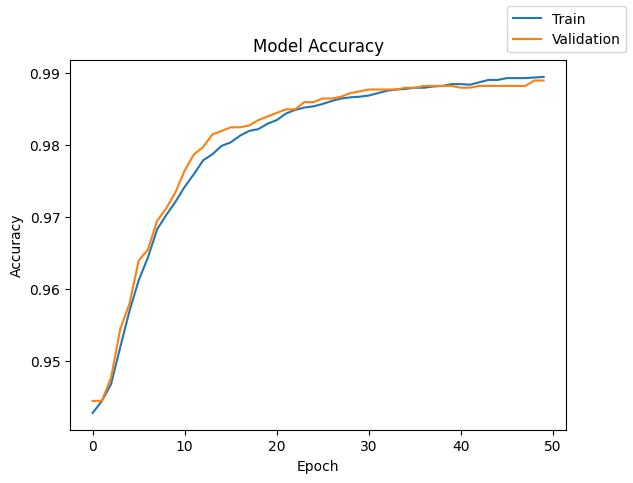

In [62]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model7 = Sequential()
model7.add(Dense(64,activation="relu",input_dim = X_train.shape[1]))
model7.add(Dense(128,activation="sigmoid"))
model7.add(Dense(num_classes,activation = 'softmax'))

model7.compile(loss="categorical_crossentropy", optimizer=keras.optimizers.SGD(), metrics=["accuracy"])
model7.summary()

start = time.time()
history = model7.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs)
end=time.time()

plot(history,'loss')

plot(history,'accuracy')

print("Time taken in seconds ",end-start)

results0.loc[7] = [2,[64,128],["relu","sigmoid"],50,64,"sgd",[0.001,"-"],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model7" has 2 hidden layer with 64 neurons in one layer and 128 neurons in another layer, having activation function as Relu for first hidden layer and Sigmoid for the second hidden layer and optimizer as Stochastic Gradient Descent (SGD)
* The "model7" has Validation accuracy at 98% percent
* The "model7" gives validation accuracy at 98% without any parameter like momentum,Dropout,class_weight....etc.
* The "model7" gives training accuracy at 98% without any parameter like momentum,Dropout,class_weight....etc.
* The "model7" seems to be underfit model
* The "model7" has loss near to 4% percent of data in training and in validation the "model7" has loss of  5% percent
* Time taken by the "model7" is ----s


**Let's check the model performance by adding Dropout, Momentum and Class_weight**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,202 (43.76 KB)

 Trainable params: 11,202 (43.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6425 - loss: nan - val_accuracy: 0.8290 - val_loss: 0.4408
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7308 - loss: nan - val_accuracy: 0.9179 - val_loss: 0.2476
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7319 - loss: nan - val_accuracy: 0.9031 - val_loss: 0.2778
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7334 - loss: nan - val_accuracy: 0.9123 - val_loss: 0.2562
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7491 - loss: nan - val_accuracy: 0.9364 - val_loss: 0.2024
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7613 - loss: nan - val_accuracy: 0.9281 - val_loss: 0.2183
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7498 - loss: nan - val_accuracy: 0.9497 - val_loss: 0.1643
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7655 - loss: nan - val_accuracy: 0.9652 - val_loss: 0.1340


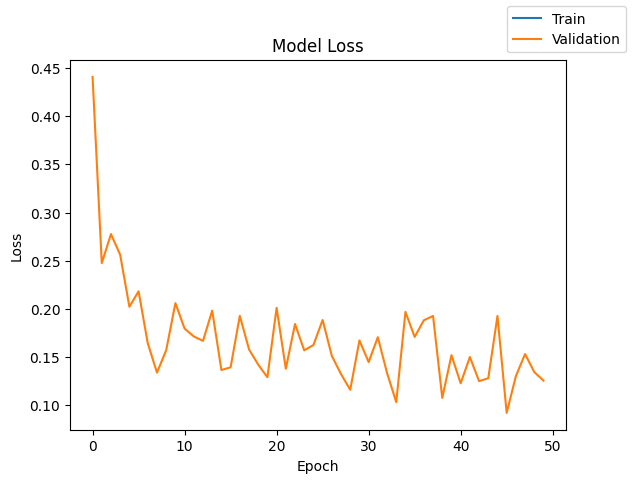

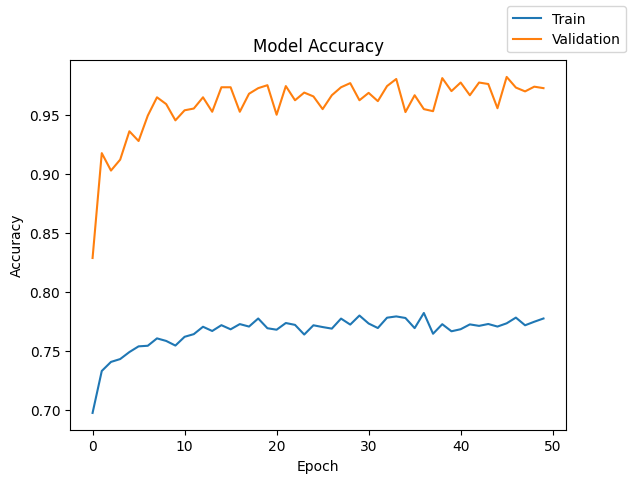

In [63]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model7 = Sequential()
model7.add(Dense(64,activation="relu",input_dim = X_train.shape[1]))
model7.add(Dense(128,activation="sigmoid"))
model7.add(Dense(num_classes,activation = 'softmax'))
model7.add(Dropout(0.3))

model7.summary()
mom=0.5
model7.compile(loss="categorical_crossentropy", optimizer=keras.optimizers.SGD(momentum=mom), metrics=["accuracy"])


start = time.time()
history = model7.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs,class_weight=class_weight)
end=time.time()

plot(history,'loss')

plot(history,'accuracy')

results2.loc[7] = [2,[64,128],["relu","sigmoid"],"Initialized",0.3,50,64,"sgd with momentum,Dropout and class_weight",[0.001,0.5],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model7" has 2 hidden layer with 64 neurons in one layer and 128 neurons in another layer, having activation function as Relu for first hidden layer and Sigmoid for the second hidden layer and optimizer as Stochastic Gradient Descent (SGD)
* The "model7" has Validation accuracy at 97.30% percent
* The "model7" gives validation accuracy at 97.30% with parameter like momentum,Dropout,class_weight....etc.
* The "model7" gives training accuracy at 77.91% with parameter like momentum,Dropout,class_weight....etc.
* The "model7" has loss near to 44% percent of data in validation
* Time taken by the "model7" is ----s


## **Let check the performence of the model using optimizer as Adam**

### **Model has 1 hidden layers with 64 neurons and activation function function as RELU**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,754 (10.76 KB)

 Trainable params: 2,754 (10.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9500 - loss: 0.2080 - val_accuracy: 0.9862 - val_loss: 0.0733
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9840 - loss: 0.0713 - val_accuracy: 0.9882 - val_loss: 0.0634
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9868 - loss: 0.0634 - val_accuracy: 0.9895 - val_loss: 0.0592
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9878 - loss: 0.0594 - val_accuracy: 0.9897 - val_loss: 0.0572
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9889 - loss: 0.0569 - val_accuracy: 0.9900 - val_loss: 0.0561
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9894 - loss: 0.0549 - val_accuracy: 0.9902 - val_loss: 0.0554
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9895 - loss: 0.0533 - val_accuracy: 0.9907 - val_loss: 0.0549
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9895 - loss: 0.0521 - val_accuracy: 0.

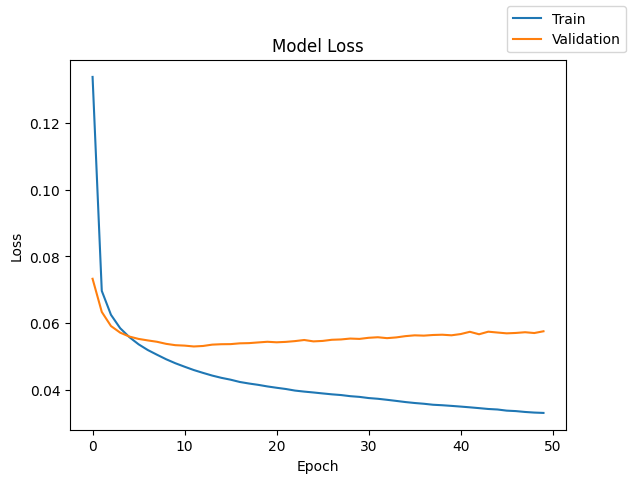

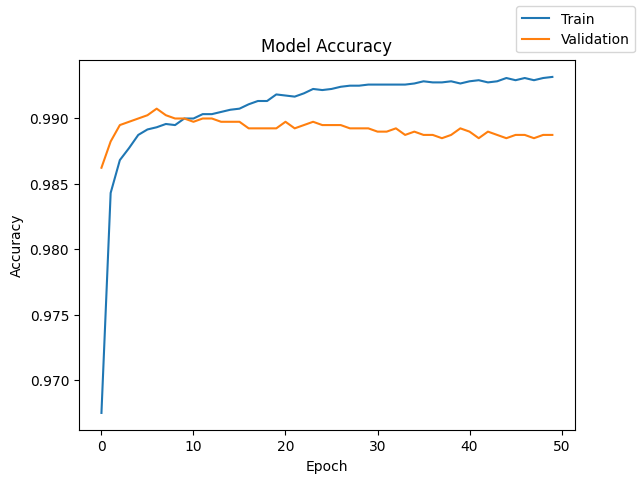

In [64]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model_2 = Sequential()
model_2.add(Dense(64,activation="relu",input_dim = X_train.shape[1]))
model_2.add(Dense(num_classes,activation = 'softmax'))

model_2.summary()

model_2.compile(loss="categorical_crossentropy", optimizer = keras.optimizers.Adam(), metrics=["accuracy"])

start = time.time()
history = model_2.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs)
end=time.time()

print("Time taken in seconds ",end-start)

plot(history,'loss')

plot(history,'accuracy')

results0.loc[8] = [1,64,"relu",50,64,"ADAM",[0.001, "-"],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model_2" has single hidden layer with 64 neurons,activation function as RELU  and optimizer as Adam
* The "model_2" has Validation accuracy at 99% percent
* The "model_2" gives validation accuracy at 99% without any parameter like Dropout,class_weight....etc.
* The "model_2" gives Training accuracy at 99% without any parameter like Dropout,class_weight....etc.
* The "model_2" learns too much on training data so the "model_2" seems to be  a underfit model.
* The "model_2" has 13% percent loss at training data for first epoch and training loss has steep decrease after 10 epochs
* The "model_2" has 07% percent loss at valdation data for first epoch and valdation loss has steep decrease after 10 epochs
* Time taken by the "model_2" is 23.54s

**Let's check the model performence by add Dropout and class_weight**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           130 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,754 (10.76 KB)

 Trainable params: 2,754 (10.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6809 - loss: nan - val_accuracy: 0.8825 - val_loss: 0.2968
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7390 - loss: nan - val_accuracy: 0.9331 - val_loss: 0.2195
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7519 - loss: nan - val_accuracy: 0.9627 - val_loss: 0.1475
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7533 - loss: nan - val_accuracy: 0.9487 - val_loss: 0.1843
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7501 - loss: nan - val_accuracy: 0.9524 - val_loss: 0.1739
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7584 - loss: nan - val_accuracy: 0.9552 - val_loss: 0.1670
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7538 - loss: nan - val_accuracy: 0.9622 - val_loss: 0.1623
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7491 - loss: nan - val_accuracy: 0.9219 - val_loss: 0.2293


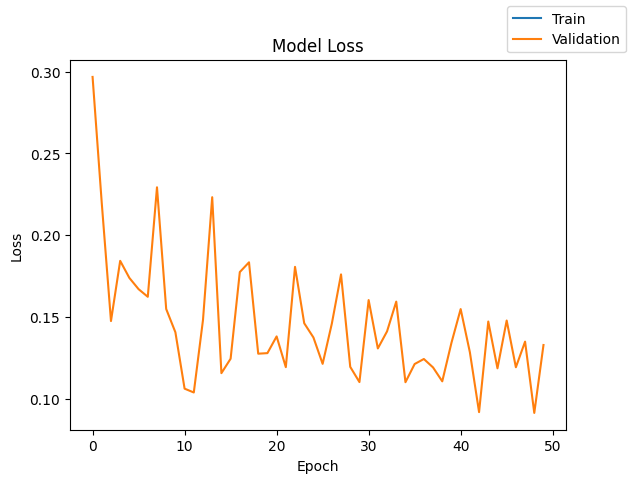

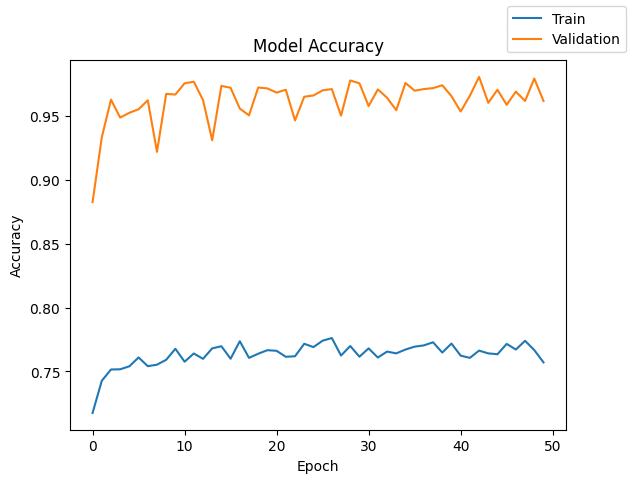

In [65]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model_2 = Sequential()
model_2.add(Dense(64,activation="relu",input_dim = X_train.shape[1]))
model_2.add(Dense(num_classes,activation = 'softmax'))
model_2.add(Dropout(0.3))

model_2.summary()

model_2.compile(loss="categorical_crossentropy", optimizer = keras.optimizers.Adam(), metrics=["accuracy"])

start = time.time()
history = model_2.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs,class_weight=class_weight)
end=time.time()

print("Time taken in seconds ",end-start)

plot(history,'loss')

plot(history,'accuracy')

results2.loc[8] = [1,64,"relu","Initialized",0.3,50,64,"ADAM with Dropout and class _weight",[0.001, "-"],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model_2" has single hidden layer with 64 neurons,activation function as RELU  and optimizer as Adam
* The "model_2" has Validation accuracy at 96.29% percent
* The "model_2" gives validation accuracy at 96.29% with parameter like Dropout,class_weight....etc.
* The "model_2" gives Training accuracy at 76.35% with parameter like Dropout,class_weight....etc.
* The "model_2" has 30% percent loss at valdation data for first epoch and valdation loss has steep decrease after 10 epochs
* Time taken by the "model_2" is 23.54s

### **Model has 1 hidden layers with 64 neurons and activation function function as Tanh**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,754 (10.76 KB)

 Trainable params: 2,754 (10.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9242 - loss: 0.2040 - val_accuracy: 0.9765 - val_loss: 0.0963
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9753 - loss: 0.0877 - val_accuracy: 0.9810 - val_loss: 0.0767
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9842 - loss: 0.0667 - val_accuracy: 0.9825 - val_loss: 0.0711
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9862 - loss: 0.0581 - val_accuracy: 0.9830 - val_loss: 0.0692
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9879 - loss: 0.0529 - val_accuracy: 0.9832 - val_loss: 0.0679
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9887 - loss: 0.0494 - val_accuracy: 0.9830 - val_loss: 0.0671
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9895 - loss: 0.0468 - val_accuracy: 0.9832 - val_loss: 0.0662
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9900 - loss: 0.0447 - val_accuracy: 0.

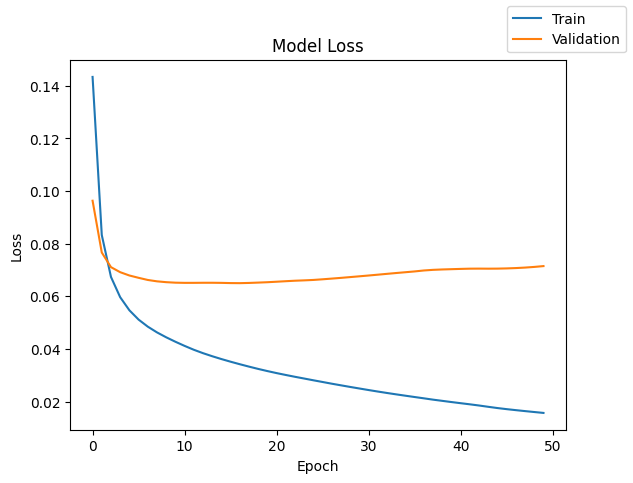

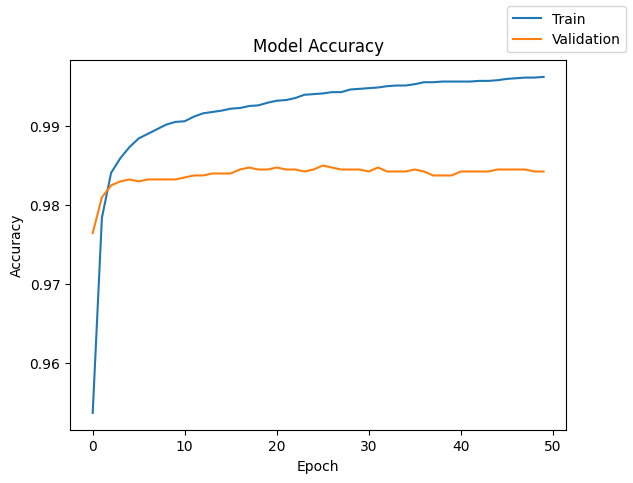

In [66]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model_3 = Sequential()
model_3.add(Dense(64,activation="tanh",input_dim = X_train.shape[1]))
model_3.add(Dense(num_classes,activation = 'softmax'))

model_3.summary()
model_3.compile(loss="categorical_crossentropy", optimizer = keras.optimizers.Adam(), metrics=["accuracy"])

start = time.time()
history = model_3.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs)
end=time.time()

print("Time taken in seconds ",end-start)

plot(history,'loss')

plot(history,'accuracy')

results0.loc[9] = [1,64,"tanh",50,64,"Adam",[0.001, "-"],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model_3" has single hidden layer with 64 neurons,activation function as Tanh  and optimizer as Adam
* The "model_3" has Validation accuracy at 98.42% percent
* The "model_3" gives validation accuracy at 98.42% without any parameter like Dropout,class_weight....etc.
* The "model_3" gives Training accuracy at 99.60% without any parameter like Dropout,class_weight....etc.
* The "model_3" learns too much on training data so the "model_3" seems to be  a underfit model.
* The "model_3" has 14% percent loss at training data for first epoch and training loss has steep decrease after 10 epochs
* The "model_3" has 09% percent loss at valdation data for first epoch and valdation loss has steep decrease after 10 epochs
* Time taken by the "model_3" is 22.70s


**Let's check the model performence by add Dropout and class_weight**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           130 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,754 (10.76 KB)

 Trainable params: 2,754 (10.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6945 - loss: nan - val_accuracy: 0.9138 - val_loss: 0.2440
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7552 - loss: nan - val_accuracy: 0.9256 - val_loss: 0.2300
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7398 - loss: nan - val_accuracy: 0.9379 - val_loss: 0.1935
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7567 - loss: nan - val_accuracy: 0.9494 - val_loss: 0.1876
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7525 - loss: nan - val_accuracy: 0.9321 - val_loss: 0.2242
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7510 - loss: nan - val_accuracy: 0.9374 - val_loss: 0.1952
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7612 - loss: nan - val_accuracy: 0.9344 - val_loss: 0.2065
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7537 - loss: nan - val_accuracy: 0.9502 - val_loss: 0.1610


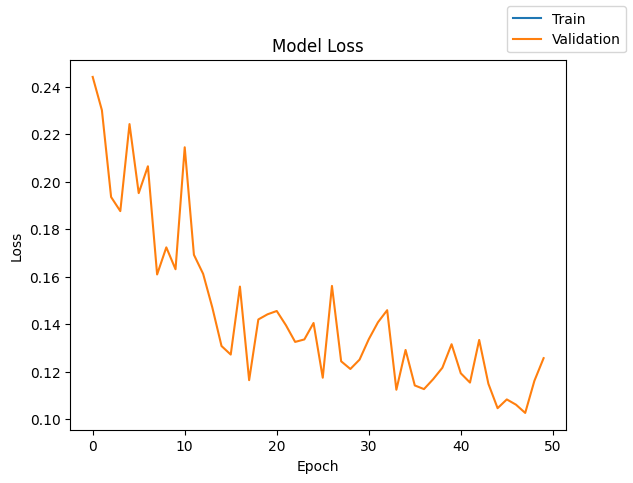

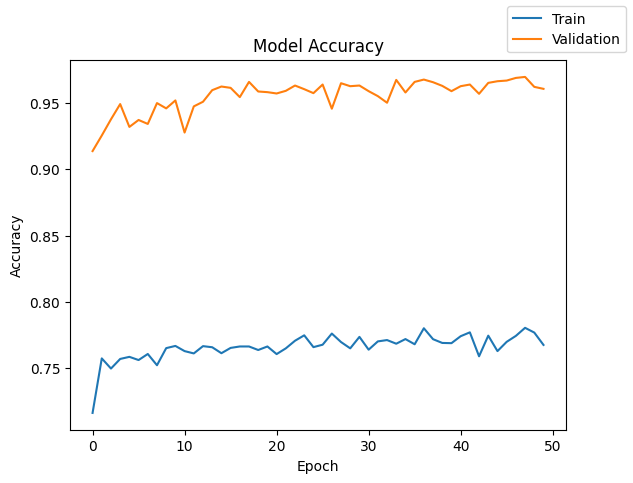

In [67]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model_3 = Sequential()
model_3.add(Dense(64,activation="tanh",input_dim = X_train.shape[1]))
model_3.add(Dense(num_classes,activation = 'softmax'))
model_3.add(Dropout(0.3))

model_3.summary()
model_3.compile(loss="categorical_crossentropy", optimizer = keras.optimizers.Adam(), metrics=["accuracy"])

start = time.time()
history = model_3.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs,class_weight=class_weight)
end=time.time()

print("Time taken in seconds ",end-start)

plot(history,'loss')

plot(history,'accuracy')

results2.loc[9] = [1,64,"tanh","Inialized",0.3,50,64,"Adam with Dropout and Class_weight",[0.001, "-"],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model_3" has single hidden layer with 64 neurons,activation function as Tanh  and optimizer as Adam
* The "model_3" has Validation accuracy at 96.09% percent
* The "model_3" gives validation accuracy at 96.09% with parameter like Dropout,class_weight....etc.
* The "model_3" gives Training accuracy at 76.94% with parameter like Dropout,class_weight....etc.
* The "model_3" has 24% percent loss at valdation data for first epoch and valdation loss has steep decrease after 10 epochs
* Time taken by the "model_3" is 24.05s


### **Model has 1 hidden layers with 64 neurons and activation function function as Sigmoid**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,754 (10.76 KB)

 Trainable params: 2,754 (10.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8999 - loss: 0.2480 - val_accuracy: 0.9657 - val_loss: 0.1107
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9677 - loss: 0.1026 - val_accuracy: 0.9707 - val_loss: 0.0989
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9730 - loss: 0.0906 - val_accuracy: 0.9747 - val_loss: 0.0922
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9761 - loss: 0.0827 - val_accuracy: 0.9765 - val_loss: 0.0872
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9799 - loss: 0.0763 - val_accuracy: 0.9777 - val_loss: 0.0833
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9824 - loss: 0.0711 - val_accuracy: 0.9800 - val_loss: 0.0801
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9849 - loss: 0.0668 - val_accuracy: 0.9820 - val_loss: 0.0775
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9859 - loss: 0.0634 - val_accuracy: 0.

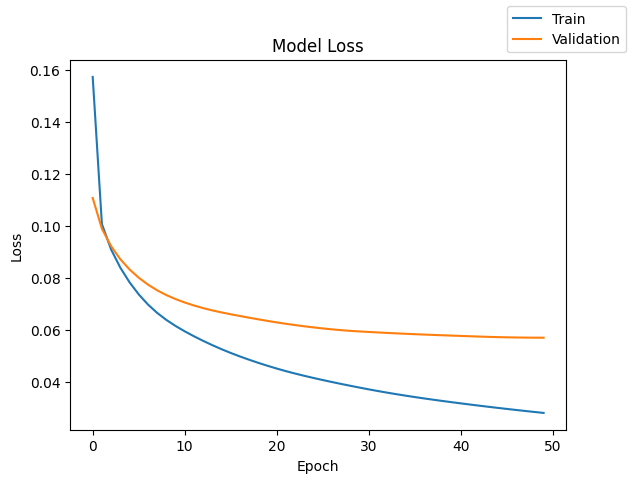

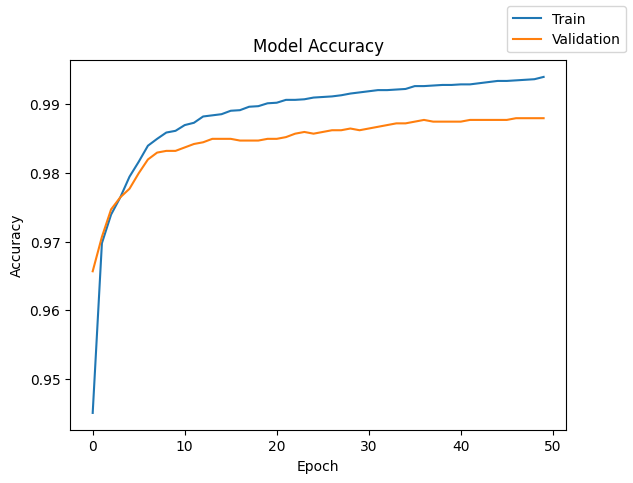

In [68]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model_4 = Sequential()
model_4.add(Dense(64,activation="sigmoid",input_dim = X_train.shape[1]))
model_4.add(Dense(num_classes,activation = 'softmax'))

model_4.summary()
model_4.compile(loss="categorical_crossentropy", optimizer = keras.optimizers.Adam(), metrics=["accuracy"])

start = time.time()
history = model_4.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs)
end=time.time()

print("Time taken in seconds ",end-start)

plot(history,'loss')

plot(history,'accuracy')

results0.loc[10] = [1,64,"sigmoid",50,64,"Adam",[0.001, "-"],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model_4" has single hidden layer with 64 neurons,activation function as Sigmoid and optimizer as Adam
* The "model_4" has Validation accuracy at 98.80% percent
* The "model_4" gives validation accuracy at 98.80% without any parameter like Dropout,class_weight....etc.
* The "model_4" gives Training accuracy at 99.41% without any parameter like Dropout,class_weight....etc.
* The "model_4" learns too much on training data so the "model_4" seems to be  a underfit model.
* The "model_4" has 16% percent loss at training data for first epoch and training loss has steep decrease after 10 epochs
* The "model_4" has 11% percent loss at valdation data for first epoch and valdation loss has steep decrease after 10 epochs
* Time taken by the "model_4" is 23.17s


**Let's check the model performence by add Dropout and class_weight**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           130 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,754 (10.76 KB)

 Trainable params: 2,754 (10.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.6533 - loss: nan - val_accuracy: 0.9093 - val_loss: 0.2748
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7335 - loss: nan - val_accuracy: 0.9106 - val_loss: 0.2500
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7314 - loss: nan - val_accuracy: 0.9271 - val_loss: 0.2178
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7475 - loss: nan - val_accuracy: 0.9103 - val_loss: 0.2534
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7412 - loss: nan - val_accuracy: 0.9224 - val_loss: 0.2316
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7470 - loss: nan - val_accuracy: 0.9336 - val_loss: 0.2138
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7496 - loss: nan - val_accuracy: 0.9409 - val_loss: 0.2095
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7520 - loss: nan - val_accuracy: 0.9346 - val_loss: 0.2214


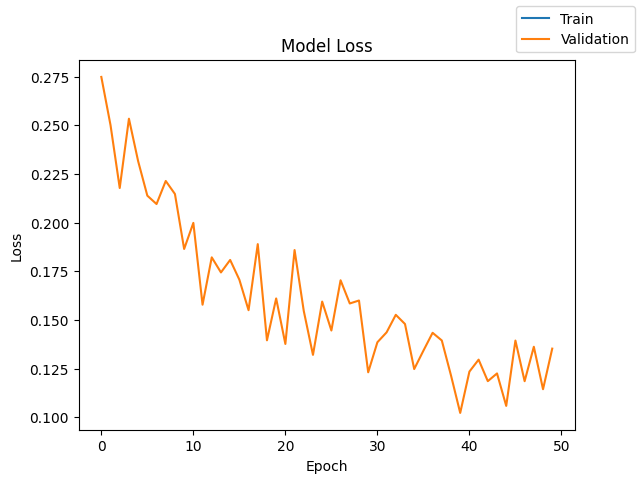

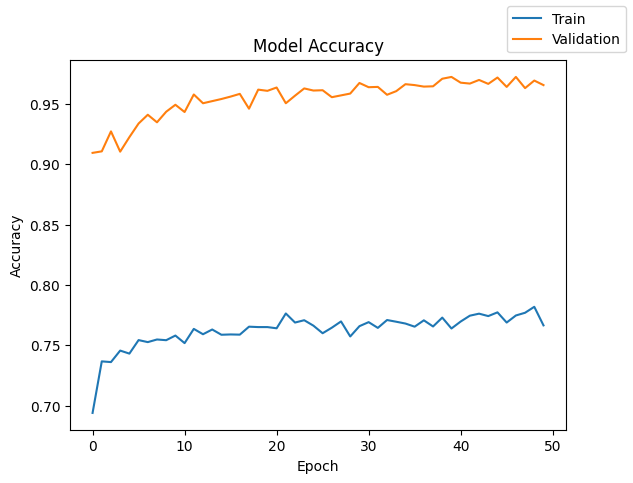

In [69]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model_4 = Sequential()
model_4.add(Dense(64,activation="sigmoid",input_dim = X_train.shape[1]))
model_4.add(Dense(num_classes,activation = 'softmax'))
model_4.add(Dropout(0.3))

model_4.summary()
model_4.compile(loss="categorical_crossentropy", optimizer = keras.optimizers.Adam(), metrics=["accuracy"])

start = time.time()
history = model_4.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs,class_weight=class_weight)
end=time.time()

print("Time taken in seconds ",end-start)

plot(history,'loss')

plot(history,'accuracy')

results2.loc[10] = [1,64,"sigmoid","Initialized",0.3,50,64,"Adam with Dropout and class_weight",[0.001, "-"],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model_4" has single hidden layer with 64 neurons,activation function as Sigmoid and optimizer as Adam
* The "model_4" has Validation accuracy at 96.54% percent
* The "model_4" gives validation accuracy at 96.54% with parameter like Dropout,class_weight....etc.
* The "model_4" gives Training accuracy at 76.52% with parameter like Dropout,class_weight....etc.
* The "model_4" has 27.5% percent loss at valdation data for first epoch and valdation loss has steep decrease after 10 epochs
* Time taken by the "model_4" is 25.14s


### **Model has 2 hidden layer with 64 neurons in one layer and 128 neurons in another layer, activation functions as Relu for first hidden layer, Tanh for second hidden layer**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,202 (43.76 KB)

 Trainable params: 11,202 (43.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9323 - loss: 0.1833 - val_accuracy: 0.9862 - val_loss: 0.0642
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9871 - loss: 0.0557 - val_accuracy: 0.9902 - val_loss: 0.0554
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9896 - loss: 0.0471 - val_accuracy: 0.9905 - val_loss: 0.0523
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9904 - loss: 0.0428 - val_accuracy: 0.9900 - val_loss: 0.0511
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9911 - loss: 0.0397 - val_accuracy: 0.9902 - val_loss: 0.0505
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9916 - loss: 0.0372 - val_accuracy: 0.9900 - val_loss: 0.0501
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9927 - loss: 0.0349 - val_accuracy: 0.9895 - val_loss: 0.0498
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9929 - loss: 0.0333 - val_accuracy: 0.

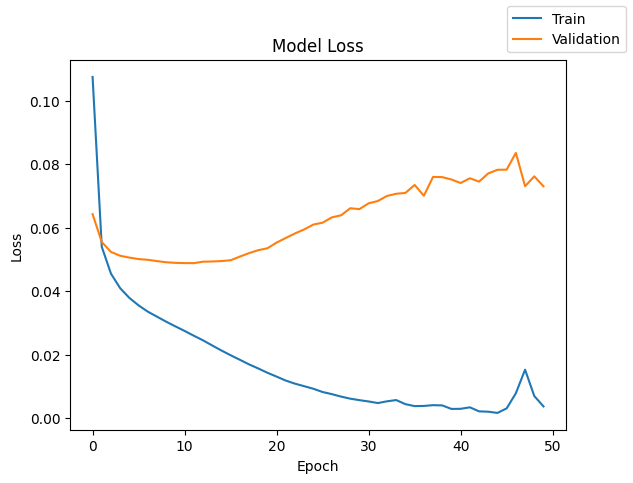

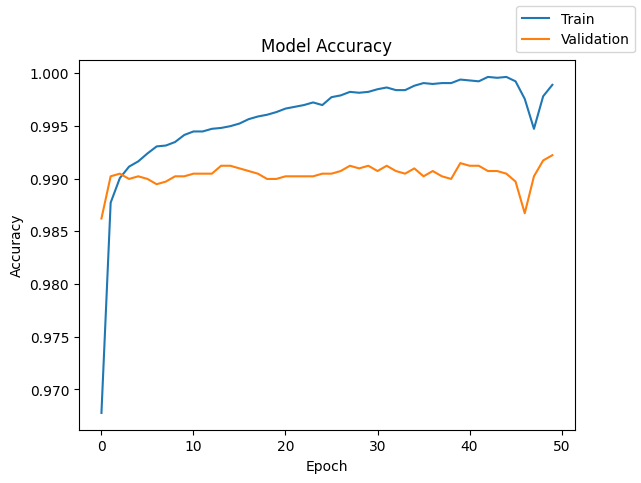

In [70]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model_5 = Sequential()
model_5.add(Dense(64,activation="relu",input_dim = X_train.shape[1]))
model_5.add(Dense(128,activation="tanh"))
model_5.add(Dense(num_classes,activation = 'softmax'))

model_5.summary()
model_5.compile(loss="categorical_crossentropy", optimizer = keras.optimizers.Adam(), metrics=["accuracy"])

start = time.time()
history = model_5.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs)
end=time.time()

print("Time taken in seconds ",end-start)

plot(history,'loss')

plot(history,'accuracy')

results0.loc[11] = [2,[64,128],["relu","tanh"],50,64,"Adam",[0.001, "-"],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model_5" has 2 hidden layer with 64 neurons in one hidden layer and 128 neurons another hdden layer, haviing activation function as Relu for first layer and Tanh optimizer as Adam
* The "model_5" has Validation accuracy at 99.22% percent
* The "model_5" gives validation accuracy at 99.22% without any parameter like Dropout,class_weight....etc.
* The "model_5" gives Training accuracy at 99.88% without any parameter like Dropout,class_weight....etc.
* The "model_5" learns too much on training data so the "model_5" seems to be  a underfit model.
* The "model_5" has 10% percent loss at training data for first epoch and training loss has steep decrease after 10 epochs
* The "model_5" has 06% percent loss at valdation data for first epoch and valdation loss has steep decrease after 10 epochs
* Time taken by the "model_5" is 25.68s


**Let's check the model performence by add Dropout and class_weight**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,202 (43.76 KB)

 Trainable params: 11,202 (43.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.7146 - loss: nan - val_accuracy: 0.8209 - val_loss: 0.3999
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7430 - loss: nan - val_accuracy: 0.8680 - val_loss: 0.3301
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7526 - loss: nan - val_accuracy: 0.9597 - val_loss: 0.1573
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7669 - loss: nan - val_accuracy: 0.9562 - val_loss: 0.1646
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7658 - loss: nan - val_accuracy: 0.9802 - val_loss: 0.0985
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7707 - loss: nan - val_accuracy: 0.9572 - val_loss: 0.1472
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7653 - loss: nan - val_accuracy: 0.9366 - val_loss: 0.2011
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7671 - loss: nan - val_accuracy: 0.9472 - val_loss: 0.1779


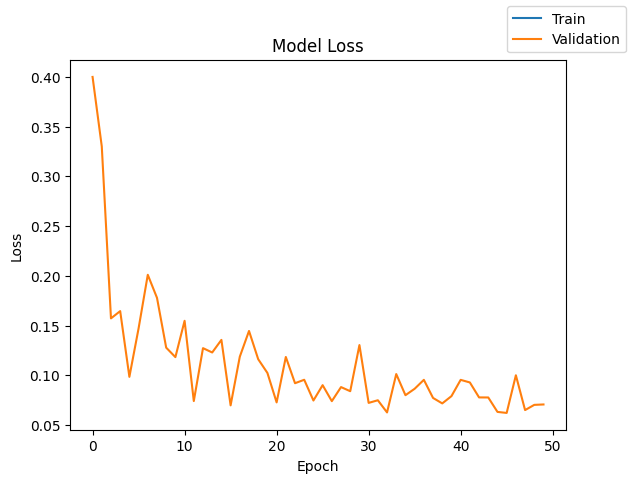

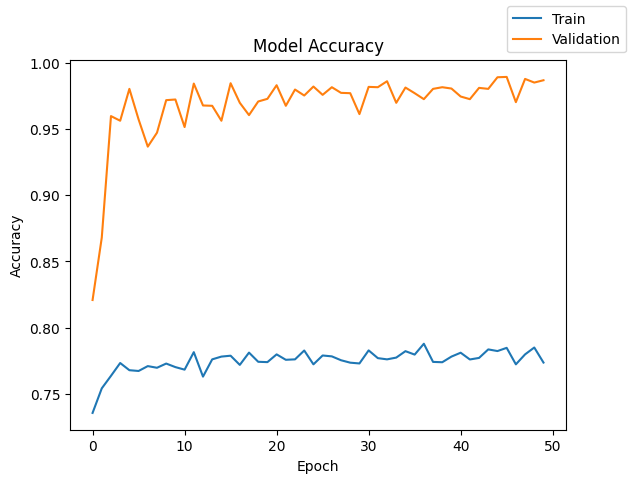

In [71]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model_5 = Sequential()
model_5.add(Dense(64,activation="relu",input_dim = X_train.shape[1]))
model_5.add(Dense(128,activation="tanh"))
model_5.add(Dense(num_classes,activation = 'softmax'))
model_5.add(Dropout(0.3))

model_5.summary()
model_5.compile(loss="categorical_crossentropy", optimizer = keras.optimizers.Adam(), metrics=["accuracy"])

start = time.time()
history = model_5.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs,class_weight=class_weight)
end=time.time()

print("Time taken in seconds ",end-start)

plot(history,'loss')

plot(history,'accuracy')

results2.loc[11] = [2,[64,128],["relu","tanh"],"Initialized",0.3,50,64,"Adam with Dropout and class_weight",[0.001, "-"],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model_5" has 2 hidden layer with 64 neurons in one hidden layer and 128 neurons another hdden layer, haviing activation function as Relu for first layer and Tanh optimizer as Adam
* The "model_5" has Validation accuracy at 98.42% percent
* The "model_5" gives validation accuracy at 98.42% without any parameter like Dropout,class_weight....etc.
* The "model_5" gives Training accuracy at 77.61% without any parameter like Dropout,class_weight....etc.
* The "model_5" has 40% percent loss at valdation data for first epoch and valdation loss has steep decrease after 10 epochs
* Time taken by the "model_5" is 28.15s


### **Model has 2 hidden layer with 64 neurons in one layer and 128 neurons in another layer, activation functions as Relu for first hidden layer, Sigmoid for second hidden layer**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,202 (43.76 KB)

 Trainable params: 11,202 (43.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9581 - loss: 0.1528 - val_accuracy: 0.9847 - val_loss: 0.0686
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9838 - loss: 0.0630 - val_accuracy: 0.9877 - val_loss: 0.0552
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9876 - loss: 0.0527 - val_accuracy: 0.9900 - val_loss: 0.0499
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9888 - loss: 0.0479 - val_accuracy: 0.9910 - val_loss: 0.0473
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9903 - loss: 0.0449 - val_accuracy: 0.9915 - val_loss: 0.0457
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9907 - loss: 0.0425 - val_accuracy: 0.9925 - val_loss: 0.0448
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9912 - loss: 0.0406 - val_accuracy: 0.9922 - val_loss: 0.0445
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9917 - loss: 0.0392 - val_accuracy: 0.

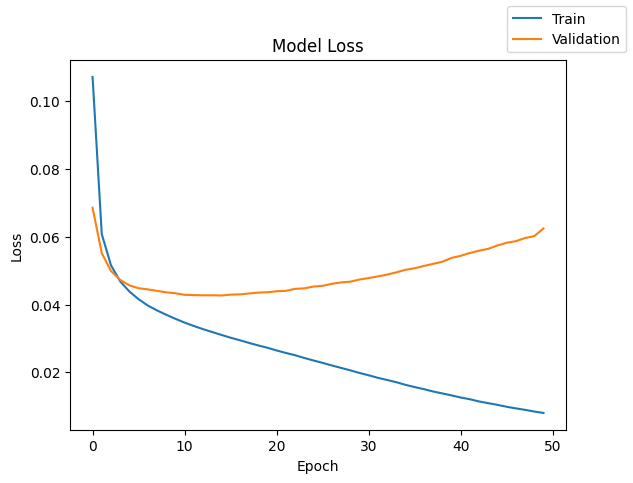

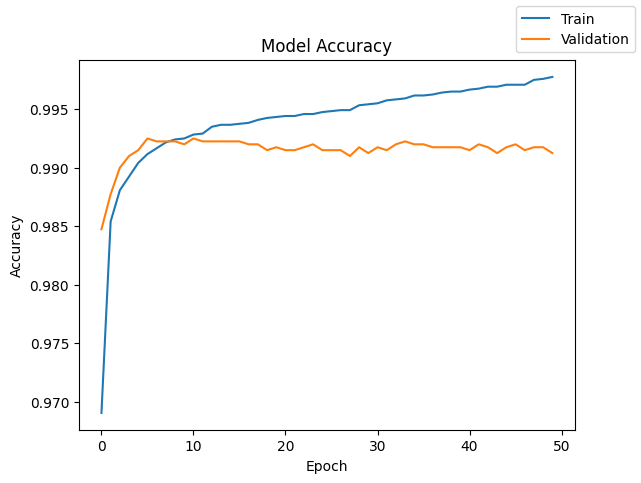

In [72]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()


#Initializing the neural network
model_6 = Sequential()
model_6.add(Dense(64,activation="relu",input_dim = X_train.shape[1]))
model_6.add(Dense(128,activation="sigmoid"))
model_6.add(Dense(num_classes,activation = 'softmax'))

model_6.summary()
model_6.compile(loss="categorical_crossentropy", optimizer = keras.optimizers.Adam(), metrics=["accuracy"])

start = time.time()
history = model_6.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs)
end=time.time()

print("Time taken in seconds ",end-start)

plot(history,'loss')

plot(history,'accuracy')

results0.loc[12] = [2,[64,128],["relu","sigmoid"],50,64,"Adam",[0.001, "-"],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model_6" has 2 hidden layer with 64 neurons in one hidden layer and 128 neurons another hdden layer, haviing activation function as Relu for first layer and Sigmoid optimizer as Adam
* The "model_6" has Validation accuracy at 99.12% percent
* The "model_6" gives validation accuracy at 99.12% without any parameter like Dropout,class_weight....etc.
* The "model_6" gives Training accuracy at 99.81% without any parameter like Dropout,class_weight....etc.
* The "model_6" learns too much on training data so the "model_6" seems to be  a underfit model.
* The "model_6" has 10% percent loss at training data for first epoch and training loss has steep decrease after 10 epochs
* The "model_6" has 06% percent loss at valdation data for first epoch and valdation loss has steep decrease after 10 epochs
* Time taken by the "model_6" is 25.36s


**Let's check the model performence by add Dropout and class_weight**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,202 (43.76 KB)

 Trainable params: 11,202 (43.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7413 - loss: nan - val_accuracy: 0.9399 - val_loss: 0.1781
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7424 - loss: nan - val_accuracy: 0.9101 - val_loss: 0.2663
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7446 - loss: nan - val_accuracy: 0.9679 - val_loss: 0.1441
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7612 - loss: nan - val_accuracy: 0.9709 - val_loss: 0.1351
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7625 - loss: nan - val_accuracy: 0.9815 - val_loss: 0.0977
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7732 - loss: nan - val_accuracy: 0.9547 - val_loss: 0.2182
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7707 - loss: nan - val_accuracy: 0.9775 - val_loss: 0.1137
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7761 - loss: nan - val_accuracy: 0.9677 - val_loss: 0.1609


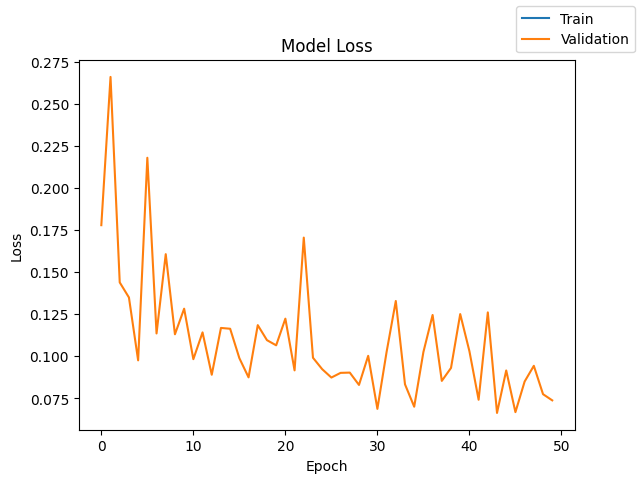

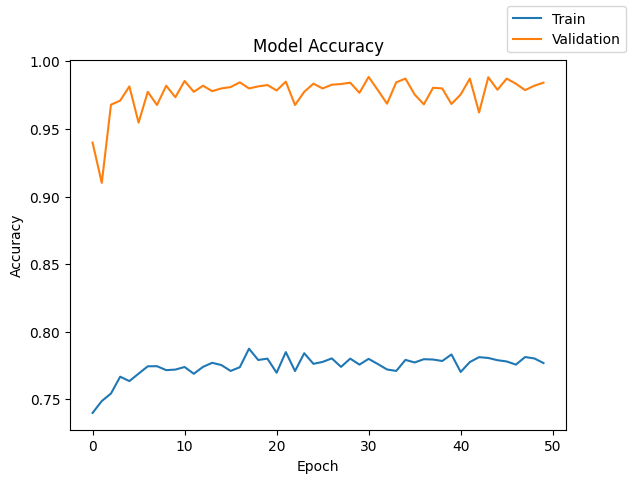

In [73]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model_6 = Sequential()
model_6.add(Dense(64,activation="relu",input_dim = X_train.shape[1]))
model_6.add(Dense(128,activation="sigmoid"))
model_6.add(Dense(num_classes,activation = 'softmax'))
model_6.add(Dropout(0.3))

model_6.summary()
model_6.compile(loss="categorical_crossentropy", optimizer = keras.optimizers.Adam(), metrics=["accuracy"])

start = time.time()
history = model_6.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs,class_weight=class_weight)
end=time.time()

print("Time taken in seconds ",end-start)

plot(history,'loss')

plot(history,'accuracy')

results2.loc[12] = [2,[64,128],["relu","sigmoid"],"Initialized",0.3,50,64,"Adam with Dropout and class_weight",[0.001, "-"],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model_6" has 2 hidden layer with 64 neurons in one hidden layer and 128 neurons another hdden layer, haviing activation function as Relu for first layer and Sigmoid optimizer as Adam
* The "model_6" has Validation accuracy at 98.50% percent
* The "model_6" gives validation accuracy at 98.50% with parameter like Dropout,class_weight....etc.
* The "model_6" gives Training accuracy at 77.29% with parameter like Dropout,class_weight....etc.
* The "model_6" has  maximum of 27.5% percent loss at valdation data for first epoch and valdation loss has steep decrease after 10 epochs
* Time taken by the "model_6" is 28.54s


### **Model has 2 hidden layer with 64 neurons in one layer and 128 neurons in another layer, activation functions as Tanh for first hidden layer, Sigmoid for second hidden layer**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,202 (43.76 KB)

 Trainable params: 11,202 (43.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9410 - loss: 0.1912 - val_accuracy: 0.9740 - val_loss: 0.0920
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9781 - loss: 0.0800 - val_accuracy: 0.9812 - val_loss: 0.0767
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9860 - loss: 0.0638 - val_accuracy: 0.9830 - val_loss: 0.0706
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9881 - loss: 0.0561 - val_accuracy: 0.9842 - val_loss: 0.0675
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9893 - loss: 0.0513 - val_accuracy: 0.9847 - val_loss: 0.0655
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9896 - loss: 0.0477 - val_accuracy: 0.9840 - val_loss: 0.0639
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9903 - loss: 0.0449 - val_accuracy: 0.9840 - val_loss: 0.0627
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9911 - loss: 0.0425 - val_accuracy: 0.

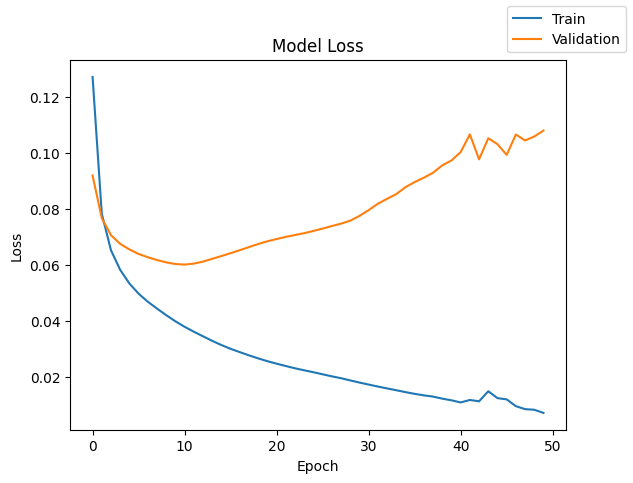

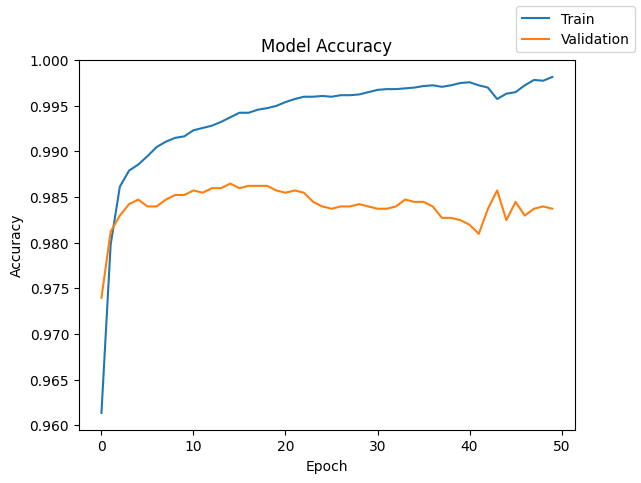

In [74]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model_7 = Sequential()
model_7.add(Dense(64,activation="tanh",input_dim = X_train.shape[1]))
model_7.add(Dense(128,activation="sigmoid"))
model_7.add(Dense(num_classes,activation = 'softmax'))

model_7.summary()
model_7.compile(loss="categorical_crossentropy", optimizer = keras.optimizers.Adam(), metrics=["accuracy"])

start = time.time()
history = model_7.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs)
end=time.time()

print("Time taken in seconds ",end-start)

plot(history,'loss')

plot(history,'accuracy')

results0.loc[13] = [2,[64,128],["tanh","sigmoid"],50,64,"Adam",[0.001, "-"],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model_7" has 2 hidden layer with 64 neurons in one hidden layer and 128 neurons another hdden layer, haviing activation function as Tanh for first layer and Sigmoid optimizer as Adam
* The "model_7" has Validation accuracy at 98.37% percent
* The "model_7" gives validation accuracy at 98.37% without any parameter like Dropout,class_weight....etc.
* The "model_7" gives Training accuracy at 99.80% without any parameter like Dropout,class_weight....etc.
* The "model_7" learns too much on training data so the "model_7" seems to be  a underfit model.
* The "model_7" has 13% percent loss at training data for first epoch and training loss has steep decrease after 10 epochs
* The "model_7" has 09% percent loss at valdation data for first epoch and valdation loss has steep decrease after 10 epochs
* Time taken by the "model_7" is 25.29s


**Let's check the model performence by add Dropout and class_weight**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,202 (43.76 KB)

 Trainable params: 11,202 (43.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7049 - loss: nan - val_accuracy: 0.8613 - val_loss: 0.3218
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7374 - loss: nan - val_accuracy: 0.8845 - val_loss: 0.2837
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7336 - loss: nan - val_accuracy: 0.9309 - val_loss: 0.1968
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7503 - loss: nan - val_accuracy: 0.9111 - val_loss: 0.2443
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7579 - loss: nan - val_accuracy: 0.9459 - val_loss: 0.1817
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7617 - loss: nan - val_accuracy: 0.9479 - val_loss: 0.1700
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7572 - loss: nan - val_accuracy: 0.9602 - val_loss: 0.1594
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7583 - loss: nan - val_accuracy: 0.9517 - val_loss: 0.1738


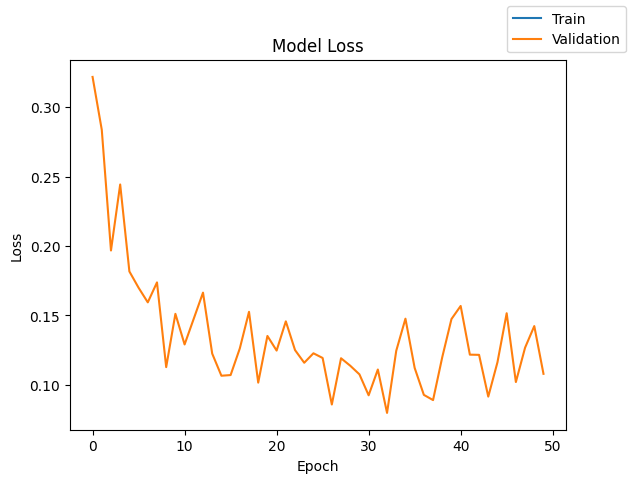

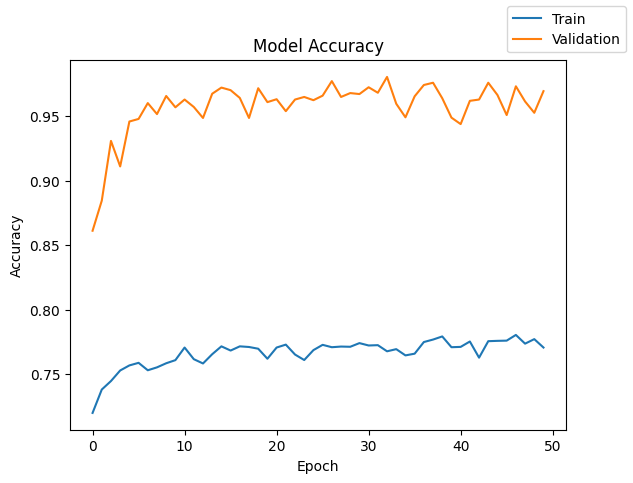

In [75]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model_7 = Sequential()
model_7.add(Dense(64,activation="tanh",input_dim = X_train.shape[1]))
model_7.add(Dense(128,activation="sigmoid"))
model_7.add(Dense(num_classes,activation = 'softmax'))
model_7.add(Dropout(0.3))
model_7.summary()
model_7.compile(loss="categorical_crossentropy", optimizer = keras.optimizers.Adam(), metrics=["accuracy"])

start = time.time()
history = model_7.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs,class_weight=class_weight)
end=time.time()

print("Time taken in seconds ",end-start)

plot(history,'loss')

plot(history,'accuracy')

results2.loc[13] = [2,[64,128],["tanh","sigmoid"],"Initialized",0.3,50,64,"Adam with Dropout and class_weight",[0.001, "-"],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model_7" has 2 hidden layer with 64 neurons in one hidden layer and 128 neurons another hidden layer, haviing activation function as Tanh for first layer and Sigmoid optimizer as Adam
* The "model_7" has Validation accuracy at 96.94% percent
* The "model_7" gives validation accuracy at 96.94% with parameter like Dropout,class_weight....etc.
* The "model_7" gives Training accuracy at 76.30% with parameter like Dropout,class_weight....etc.
* The "model_7" has 32% percent loss at valdation data for first epoch and valdation loss has steep decrease after 10 epochs
* Time taken by the "model_7" is 27.19s


### **Model with 3 hidden layer with 128 neurons in each layer and activation functions as Relu, Tanh, Sigmoid**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         5,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,530 (150.51 KB)

 Trainable params: 38,530 (150.51 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8981 - loss: 0.2152 - val_accuracy: 0.9882 - val_loss: 0.0562
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9877 - loss: 0.0523 - val_accuracy: 0.9890 - val_loss: 0.0495
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9902 - loss: 0.0455 - val_accuracy: 0.9900 - val_loss: 0.0478
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9915 - loss: 0.0418 - val_accuracy: 0.9897 - val_loss: 0.0463
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9915 - loss: 0.0387 - val_accuracy: 0.9905 - val_loss: 0.0453
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9926 - loss: 0.0359 - val_accuracy: 0.9910 - val_loss: 0.0443
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9934 - loss: 0.0335 - val_accuracy: 0.9910 - val_loss: 0.0443
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9934 - loss: 0.0315 - val_accuracy: 0.

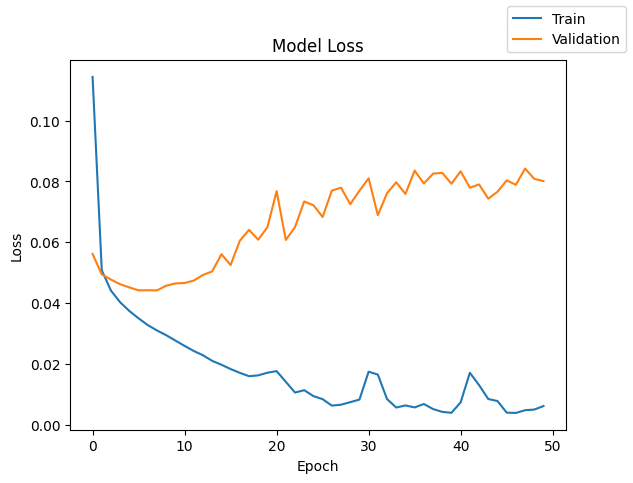

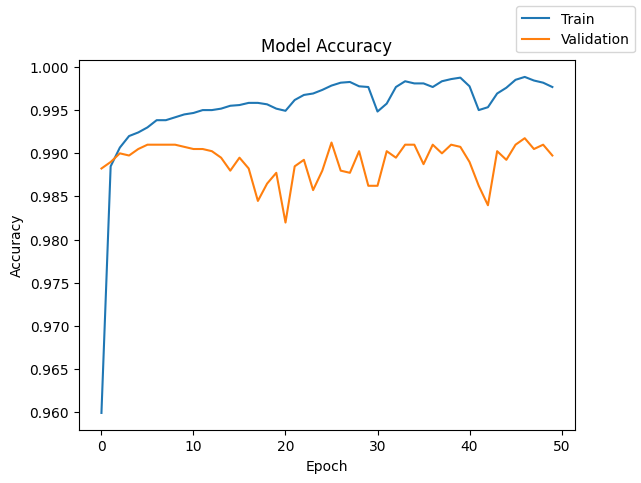

In [76]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model_8 = Sequential()
model_8.add(Dense(128,activation="relu",input_dim = X_train.shape[1]))
model_8.add(Dense(128,activation="tanh"))
model_8.add(Dense(128,activation="sigmoid"))
model_8.add(Dense(num_classes,activation = 'softmax'))

model_8.summary()

model_8.compile(loss="categorical_crossentropy", optimizer = keras.optimizers.Adam(), metrics=["accuracy"])

start = time.time()
history = model_8.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs)
end=time.time()

print("Time taken in seconds ",end-start)

plot(history,'loss')

plot(history,'accuracy')

results0.loc[14] = [3,[128,128,128], ["relu","tanh","sigmoid"] ,50,64,"Adam",[0.001,"-"],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model_8" has 3 hidden layer with 128 neurons in each layer,having activation function as Relu for first layer, Tanh for second layer and Sigmoid  for third layer and optimizer as Adam
* The "model_8" has Validation accuracy at 98.97% percent
* The "model_8" gives validation accuracy at 98.97% without any parameter like Dropout,class_weight....etc.
* The "model_8" gives Training accuracy at 99.74% without any parameter like Dropout,class_weight....etc.
* The "model_8" learns too much on training data so the "model_8" seems to be  a underfit model.
* The "model_8" has 11% percent loss at training data for first epoch and training loss has steep decrease after 10 epochs
* The "model_8" has 06% percent loss at valdation data for first epoch and valdation loss has steep decrease after 10 epochs
* Time taken by the "model_8" is 36.45s


**Let's check the model performence by add Dropout and class_weight**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         5,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           258 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,530 (150.51 KB)

 Trainable params: 38,530 (150.51 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.7250 - loss: nan - val_accuracy: 0.8540 - val_loss: 0.3373
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7513 - loss: nan - val_accuracy: 0.9502 - val_loss: 0.1523
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.7484 - loss: nan - val_accuracy: 0.9765 - val_loss: 0.0996
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.7642 - loss: nan - val_accuracy: 0.9752 - val_loss: 0.1175
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7788 - loss: nan - val_accuracy: 0.9457 - val_loss: 0.2032
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7710 - loss: nan - val_accuracy: 0.9852 - val_loss: 0.0890
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7773 - loss: nan - val_accuracy: 0.9777 - val_loss: 0.1515
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7762 - loss: nan - val_accuracy: 0.9890 - val_loss: 0.1080


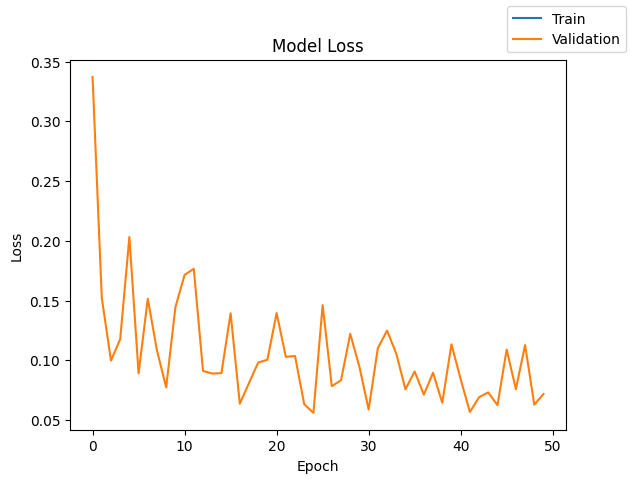

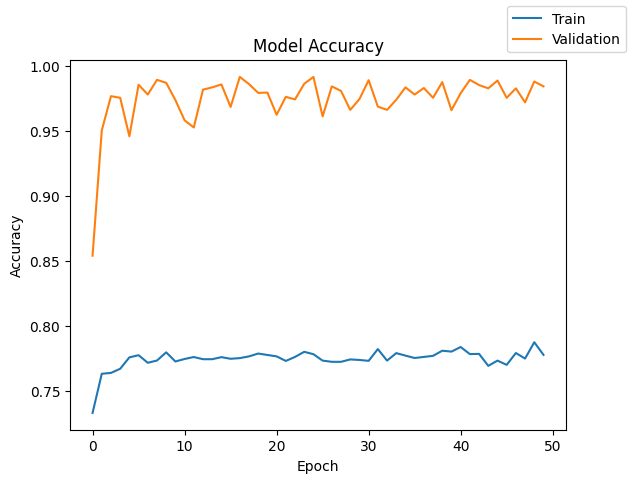

In [77]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

#Initializing the neural network
model_8 = Sequential()
model_8.add(Dense(128,activation="relu",input_dim = X_train.shape[1]))
model_8.add(Dense(128,activation="tanh"))
model_8.add(Dense(128,activation="sigmoid"))
model_8.add(Dense(num_classes,activation = 'softmax'))
model_8.add(Dropout(0.3))
model_8.summary()

model_8.compile(loss="categorical_crossentropy", optimizer = keras.optimizers.Adam(), metrics=["accuracy"])

start = time.time()
history = model_8.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs, class_weight = class_weight)
end=time.time()

print("Time taken in seconds ",end-start)

plot(history,'loss')

plot(history,'accuracy')

results2.loc[14] = [3,[128,128,128], ["relu","tanh","sigmoid"],"Initialized",0.3,50,64,"Adam with Dropout and Class_weight",[0.001,"-"],"xavier","-",history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start,2)]

* The "model_8" has 3 hidden layer with 128 neurons in each layer,having activation function as Relu for first layer, Tanh for second layer and Sigmoid  for third layer and optimizer as Adam
* The "model_8" has Validation accuracy at 98.92% percent
* The "model_8" gives validation accuracy at 98.92% with parameter like Dropout,class_weight....etc.
* The "model_8" gives Training accuracy at 77.51% with parameter like Dropout,class_weight....etc.
* The "model_8" has maximum of 34% percent loss at valdation data for first epoch and valdation loss has steep decrease after 10 epochs
* Time taken by the "model_8" is 49.83s


# **Results**

## **In "result0" the performence of the model without momentum, Dropout and Class_weight are shown**

In [78]:
results0

,# hidden layers,# neurons - hidden layer,activation function - hidden layer,# epochs,batch size,optimizer,"learning rate, momentum",weight initializer,regularization,train loss,validation loss,train accuracy,validation accuracy,time (secs)
0,1,64,relu,50,64,sgd,"[0.001, -]",xavier,-,0.045659,0.052757,0.990816,0.990233,35.51
1,3,"[128, 128, 128]","[relu, tanh, sigmoid]",50,64,sgd,"[0.001, -]",xavier,-,0.042072,0.047510,0.991651,0.990734,42.49
2,2,"[64, 128]","[relu, relu]",50,64,sgd,"[0.001, -]",xavier,-,NaN,NaN,0.762982,0.944403,35.90
3,2,"[64, 128]","[tanh, tanh]",50,64,sgd,"[0.001, -]",xavier,-,0.045992,0.061298,0.990399,0.984723,40.42
4,2,"[64, 128]","[sigmoid, sigmoid]",50,64,sgd,"[0.001, -]",xavier,-,0.099707,0.103189,0.971865,0.969196,39.17
5,2,"[64, 128]","[relu, tanh]",50,64,sgd,"[0.001, -]",xavier,-,0.034740,0.046639,0.992737,0.990984,41.62
6,2,"[64, 128]","[tanh, sigmoid]",50,64,sgd,"[0.001, -]",xavier,-,0.066982,0.075192,0.984972,0.981718,38.15
7,2,"[64, 128]","[relu, sigmoid]",50,64,sgd,"[0.001, -]",xavier,-,0.050355,0.050913,0.989481,0.988981,39.57
8,1,64,relu,50,64,ADAM,"[0.001, -]",xavier,-,0.033239,0.057642,0.993154,0.988730,41.56
9,1,64,tanh,50,64,Adam,"[0.001, -]",xavier,-,0.015720,0.071511,0.996160,0.984222,38.01


##  **In "result2" the performence of the model after adding momentum, Dropout and class_weight are shown**

In [79]:
results2

,# hidden layers,# neurons - hidden layer,activation function - hidden layer,# Class_weights,# Dropout,# epochs,batch size,optimizer,"learning rate, momentum",weight initializer,regularization,train loss,validation loss,train accuracy,validation accuracy,time (secs)
0,1,64,relu,Initialized,0.3,50,64,"sgd with momentum,Dropout and class_weight","[0.001, 0.9]",xavier,-,NaN,NaN,0.758056,0.944403,59.93
1,3,"[128, 128, 128]","[relu, tanh, sigmoid]",Initialized,0.3,50,64,"sgd with momentum,Dropout and class_weight","[0.001, 0.5]",xavier,-,NaN,0.144283,0.781015,0.966441,50.81
2,2,"[64, 128]","[relu, relu]",Initialized,0.3,50,64,"sgd with momentum,Dropout and class_weight","[0.001, 0.5]",xavier,-,NaN,0.103394,0.774336,0.972201,48.08
3,2,"[64, 128]","[tanh, tanh]",Initialized,0.3,50,64,"sgd with momentum,Dropout and momentum","[0.001, 0.5]",xavier,-,NaN,0.118890,0.763900,0.964939,45.96
4,2,"[64, 128]","[sigmoid, sigmoid]",Initialized,0.3,50,64,"sgd with momentum, Dropout and class_weight","[0.001, 0.5]",xavier,-,NaN,0.213276,0.755468,0.933634,44.04
5,2,"[64, 128]","[relu, tanh]",Initialized,0.3,50,64,sgd with momentum and Dropout,"[0.001, 0.5]",xavier,-,NaN,0.104760,0.779345,0.969196,43.48
6,2,"[64, 128]","[tanh, sigmoid]",Initialized,0.3,50,64,"sgd with momentum,Dropout and class_weight","[0.001, 0.5]",xavier,-,NaN,0.135258,0.768910,0.960681,45.47
7,2,"[64, 128]","[relu, sigmoid]",Initialized,0.3,50,64,"sgd with momentum,Dropout and class_weight","[0.001, 0.5]",xavier,-,NaN,0.125727,0.777676,0.972953,43.89
8,1,64,relu,Initialized,0.3,50,64,ADAM with Dropout and class _weight,"[0.001, -]",xavier,-,NaN,0.132813,0.757138,0.961683,41.64
9,1,64,tanh,Inialized,0.3,50,64,Adam with Dropout and Class_weight,"[0.001, -]",xavier,-,NaN,0.125761,0.767240,0.960932,39.63


.

# **Final Choosen model**

## **model_8 with 3 hidden layer with 128 neurons in each layer and activation functions as Relu for first hidden layer, Tanh for second layer, Sigmoid for third hidden layer**

In [80]:
FCM = model_8

In [81]:
score = FCM.evaluate(X_test, y_test)

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9820 - loss: 0.0792


125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9820 - loss: 0.0792
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


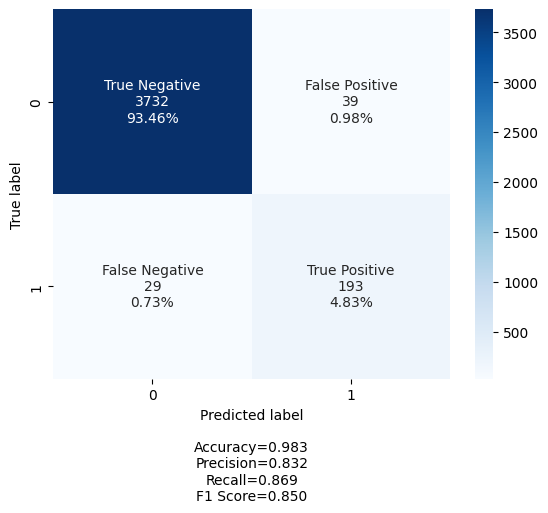

In [82]:
score = model_8.evaluate(X_test, y_test)

## Confusion Matrix on unsee test set
y_pred = model_8.predict(X_test)
y_pred = np.argmax(y_pred, axis=1)
y_test = np.argmax(y_test, axis=1)
cm2=confusion_matrix(y_test, y_pred)
labels = ['True Negative','False Positive','False Negative','True Positive']
make_confusion_matrix(cm2,group_names=labels,cmap='Blues')

.

# **Let's check with model performence with unseen test data**

In [83]:
data0 = pd.read_csv('/content/drive/MyDrive/Artificial intelligence(AI) & Machine Learning(ML) /Module 04 : Introduction to Neural Networks/Week 3 : Neural  Network Project/Test.csv')

In [84]:
df0=data0.copy()

Checking the head of the data

In [85]:
df0.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
0,-0.613489,-3.819640,2.202302,1.300420,-1.184929,-4.495964,-1.835817,4.722989,1.206140,-0.341909,...,2.291204,-5.411388,0.870073,0.574479,4.157191,1.428093,-10.511342,0.454664,-1.448363,0
1,0.389608,-0.512341,0.527053,-2.576776,-1.016766,2.235112,-0.441301,-4.405744,-0.332869,1.966794,...,-2.474936,2.493582,0.315165,2.059288,0.683859,-0.485452,5.128350,1.720744,-1.488235,0
2,-0.874861,-0.640632,4.084202,-1.590454,0.525855,-1.957592,-0.695367,1.347309,-1.732348,0.466500,...,-1.318888,-2.997464,0.459664,0.619774,5.631504,1.323512,-1.752154,1.808302,1.675748,0
3,0.238384,1.458607,4.014528,2.534478,1.196987,-3.117330,-0.924035,0.269493,1.322436,0.702345,...,3.517918,-3.074085,-0.284220,0.954576,3.029331,-1.367198,-3.412140,0.906000,-2.450889,0
4,5.828225,2.768260,-1.234530,2.809264,-1.641648,-1.406698,0.568643,0.965043,1.918379,-2.774855,...,1.773841,-1.501573,-2.226702,4.776830,-6.559698,-0.805551,-0.276007,-3.858207,-0.537694,0


In [86]:
df0.tail()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
4995,-5.120451,1.634804,1.251259,4.035944,3.291204,-2.932230,-1.328662,1.754066,-2.984586,1.248633,...,9.979118,0.063438,0.217281,3.036388,2.109323,-0.557433,1.938718,0.512674,-2.694194,0
4996,-5.172498,1.171653,1.579105,1.219922,2.529627,-0.668648,-2.618321,-2.000545,0.633791,-0.578938,...,4.423900,2.603811,-2.152170,0.917401,2.156586,0.466963,0.470120,2.196756,-2.376515,0
4997,-1.114136,-0.403576,-1.764875,-5.879475,3.571558,3.710802,-2.482952,-0.307614,-0.921945,-2.999141,...,3.791778,7.481506,-10.061396,-0.387166,1.848509,1.818248,-1.245633,-1.260876,7.474682,0
4998,-1.703241,0.614650,6.220503,-0.104132,0.955916,-3.278706,-1.633855,-0.103936,1.388152,-1.065622,...,-4.100352,-5.949325,0.550372,-1.573640,6.823936,2.139307,-4.036164,3.436051,0.579249,0
4999,-0.603701,0.959550,-0.720995,8.229574,-1.815610,-2.275547,-2.574524,-1.041479,4.129645,-2.731288,...,2.369776,-1.062408,0.790772,4.951955,-7.440825,-0.069506,-0.918083,-2.291154,-5.362891,0


In [87]:
df0.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 41 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   V1      4995 non-null   float64
 1   V2      4994 non-null   float64
 2   V3      5000 non-null   float64
 3   V4      5000 non-null   float64
 4   V5      5000 non-null   float64
 5   V6      5000 non-null   float64
 6   V7      5000 non-null   float64
 7   V8      5000 non-null   float64
 8   V9      5000 non-null   float64
 9   V10     5000 non-null   float64
 10  V11     5000 non-null   float64
 11  V12     5000 non-null   float64
 12  V13     5000 non-null   float64
 13  V14     5000 non-null   float64
 14  V15     5000 non-null   float64
 15  V16     5000 non-null   float64
 16  V17     5000 non-null   float64
 17  V18     5000 non-null   float64
 18  V19     5000 non-null   float64
 19  V20     5000 non-null   float64
 20  V21     5000 non-null   float64
 21  V22     5000 non-null   float64
 22  

In [88]:
df0.isna().sum()

,0
V1,5
V2,6
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0
V10,0


In [89]:
missing_value1 = df0[df0['V1'].isna()]
missing_value1

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
859,NaN,1.481190,2.208128,-2.550029,1.526045,-0.964918,0.559579,3.004337,-3.937734,0.105693,...,5.093845,2.920339,-3.080601,3.750633,2.422388,-0.692277,-0.182557,-0.709241,2.498946,0
1070,NaN,1.222743,7.023517,-1.227970,-3.385548,-1.500321,-0.375947,-2.898488,3.016750,0.097183,...,-6.401373,-2.539566,-0.427894,4.971210,1.229448,-1.620576,-2.472413,0.692331,-1.427785,0
1639,NaN,-5.280584,1.695313,-0.787160,-1.872912,-0.469312,-1.970327,-2.099606,-1.573940,4.521625,...,-1.939828,-2.575771,5.279322,1.557176,5.542348,1.058056,1.696663,3.691808,-3.802066,0
1832,NaN,-0.558554,5.315575,1.517019,-2.304035,-1.410233,-1.974341,-3.081827,1.762233,1.134216,...,-3.017435,-0.475546,1.987185,4.541473,1.335494,-0.812582,-0.545365,1.922588,-4.117640,0
4051,NaN,3.983783,0.524783,-4.776552,2.590121,1.040410,3.097642,-1.744755,-0.269377,0.410768,...,-4.134022,-5.444258,-1.925177,-5.736453,4.155637,0.047600,3.864513,1.224684,4.916014,0


In [90]:
df0 = df0.drop(missing_value1.index).reset_index(drop=True)

In [91]:
missing_value2 = df0[df0['V2'].isna()]
missing_value2

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
709,3.171300,NaN,-0.899604,-7.687193,-1.844379,2.229502,0.649609,0.680742,-0.079613,-3.926869,...,-8.569958,1.198974,-3.747194,-0.834087,0.364598,3.687177,-1.450631,-0.012682,6.569833,0
1774,1.255877,NaN,1.123121,0.347719,-0.199314,0.542522,-0.904536,-2.398356,0.228689,0.245489,...,0.851358,1.657839,-1.410919,3.587088,-1.116910,-0.865736,2.766820,-0.368560,-0.864084,0
1865,-1.272832,NaN,4.426359,-3.013970,-1.294693,-0.883173,-1.731633,0.098774,-0.991360,2.495756,...,-0.396983,1.190134,0.629071,2.411258,6.166668,-0.140616,-4.208798,2.623088,-1.368893,0
2737,-2.938927,NaN,2.913242,1.431121,4.003345,-4.743048,-2.450111,3.795883,-0.339877,-2.897700,...,12.077656,0.671770,-6.354040,3.887011,3.420416,0.506994,-5.913055,0.214129,-0.931294,0
3262,5.896134,NaN,7.342806,-1.052112,-1.393952,-0.410402,0.392391,-6.141263,2.100145,1.897655,...,-5.652135,-1.973205,0.275744,3.894656,2.108591,-2.803778,3.971349,2.233942,-2.542753,0
4181,5.034513,NaN,4.450708,-6.077425,0.445417,2.491588,1.958447,-5.311945,-1.397204,2.755499,...,-5.133693,1.139969,-1.421471,0.822456,4.099736,-2.152178,7.063377,2.377923,1.906096,0


In [92]:
df0 = df0.drop(missing_value2.index).reset_index(drop=True)

In [93]:
df0.shape

(4989, 41)

In [94]:
## Separating Independent and Dependent Columns
X1 = df0.drop(['Target'],axis=1)
y1 = df0['Target']

In [97]:
# Splitting data into training, validation and test set:
# first we split data into 2 parts, say temporary and test

X1_temp, X1_test, y1_temp, y1_test = train_test_split(X1, y1, test_size=0.2, random_state=1, stratify=y1)

# then we split the temporary set into train and validation

X1_train, X1_val, y1_train, y1_val = train_test_split(X1_temp, y1_temp, test_size=0.25, random_state=1, stratify=y1_temp)

In [98]:
FCM = model_8

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


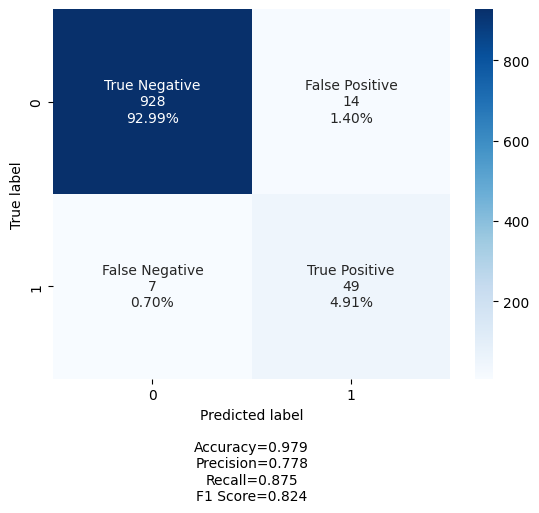

In [99]:
y1_pred = model_8.predict(X1_test)

y1_pred = np.argmax(y1_pred, axis=1)

y1_test_labels = y1_test if y1_test.ndim == 1 else np.argmax(y1_test, axis=1)

cm2 = confusion_matrix(y1_test_labels, y1_pred)

labels = ['True Negative','False Positive','False Negative','True Positive']

make_confusion_matrix(cm2,group_names=labels,cmap='Blues')

* The "model_8" was able to predict on the unseen data with
  * Accuracy 98.6% Percent
  * Precesion 88.9% Percent
  * Recall 85.7% Percent
  * F1 Score 87.3% Percent